# Projekt 1: Rating/Scoring: modele, wyjaśnialność, kalibracja 4%, ratingi (pkt 3.3–3.6)

**Notebook 02.** Wymaga uruchomionego notebooka 01 (katalog `artifacts/` oraz `src/preprocessing.py`).

Zawartość:

0. Konfiguracja, wczytanie artefaktów
1. **3.3 Model interpretowalny** – scorecard: regresja logistyczna na WoE (selekcja po znaku i VIF), jakość, interpretacja globalna i lokalna, stabilność
2. **3.4 Model black-box** – LightGBM, tuning z kontrolą overfittingu, SHAP, LIME, what-if
3. **Wierność i stabilność wyjaśnień** (eksperymenty obowiązkowe)
4. **Porównanie modeli i zamrożenie modeli**
5. **3.5 Kalibracja** – statystyczna (Platt / izotoniczna / beta) i dostosowanie do PD = 4%
6. **3.6 Progi decyzji, ratingi, audyt podgrup, analiza kontrfaktyczna**
7. Podsumowanie, eksport, requirements.txt

## 0. Konfiguracja

In [1]:
# importy bibliotek
import os
import sys
import json
import hashlib
import warnings
import platform
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import lightgbm as lgb
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import loguniform, randint, uniform, spearmanr
from scipy.special import expit, logit
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ParameterSampler, StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss, roc_curve, precision_recall_curve, cohen_kappa_score

# wyłączamy ostrzeżenia, żeby nie zaśmiecały wyników
warnings.filterwarnings("ignore")


def format_liczby(v):
    """Format liczb w tabelach pandas: separator tysięcy i 4 miejsca po przecinku."""
    return f"{v:,.4f}"


pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", format_liczby)
sns.set_theme(style="whitegrid")

SEED = 42
ART = "artifacts"

# tworzymy foldery, jeśli jeszcze nie istnieją
for d in ["src", "figures", ART]:
    os.makedirs(d, exist_ok=True)

# sprawdzamy, czy notebook 01 został uruchomiony
assert os.path.exists(f"{ART}/splits.json") and os.path.exists("src/preprocessing.py"), "Najpierw uruchom notebook 01."

C:\Users\Maciek\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%%writefile src/scorecard.py
"""Narzędzia do projektu 1 (część 2): Model interpretowalny (scorecard),
metryki, kalibracja, ratingi.
"""
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.special import expit, logit
from scipy.stats import ks_2samp
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
    roc_curve,
)

EPS = 1e-6


def clip_p(p):
    """Przycina prawdopodobienstwa do przedzialu [EPS, 1-EPS], zeby logit i log byly skonczone."""
    return np.clip(np.asarray(p, float), EPS, 1 - EPS)


# ---------------------------------------------------------------- VIF
def vif_series(X):
    """Liczy VIF kazdej kolumny z odwrotnosci macierzy korelacji.
    Wejscie: tabela z cechami. Wynik: Series z VIF dla kazdej cechy."""
    X = pd.DataFrame(X)
    # dla jednej cechy nie ma wspolliniowosci, VIF = 1
    if X.shape[1] == 1:
        return pd.Series([1.0], index=X.columns)
    R = np.corrcoef(X.values, rowvar=False)
    R = np.nan_to_num(R)
    np.fill_diagonal(R, 1.0)
    odwrotna = np.linalg.pinv(R)
    return pd.Series(np.diag(odwrotna), index=X.columns)


# ---------------------------------------------------------------- Scorecard
class ScorecardLR(BaseEstimator, ClassifierMixin):
    """Regresja logistyczna na cechach WoE z automatyczna selekcja cech:
       (1) L1 -> usuwa cechy o zerowym wspolczynniku lub 'zlym' znaku,
       (2) iteracyjne usuwanie cechy o najwyzszym VIF az VIF <= vif_max,
       (3) opcjonalny limit liczby cech (zostaja te z najwiekszym |wspolczynnikiem|),
       (4) koncowy model L2; cechy z nieoczekiwanym znakiem sa usuwane i procedura sie powtarza.
    WoE = ln(%bad/%good), wiec oczekiwany znak wspolczynnika = +1 (wyzsze WoE = wyzsze ryzyko)."""

    def __init__(self, C_l1=0.1, C_final=1.0, vif_max=5.0, max_features=None, expected_sign=1):
        self.C_l1 = C_l1
        self.C_final = C_final
        self.vif_max = vif_max
        self.max_features = max_features
        self.expected_sign = expected_sign

    def fit(self, X, y):
        """Uczy model: w petli odrzuca cechy (zly znak, wysoki VIF, limit liczby cech), az zostanie dobry zestaw."""
        X = pd.DataFrame(X)
        y = np.asarray(y)
        sg = self.expected_sign
        cols = list(X.columns)
        final = None

        for krok in range(300):
            # krok 1: L1 - zostawiamy tylko cechy z wlasciwym znakiem wspolczynnika
            l1 = LogisticRegression(penalty="l1", solver="liblinear", C=self.C_l1, max_iter=2000)
            l1.fit(X[cols], y)
            c1 = pd.Series(l1.coef_[0], cols)
            keep = []
            for c in cols:
                if c1[c] * sg > 1e-8:
                    keep.append(c)
            if len(keep) == 0:
                # gdy wszystkie odpadly, zostawiamy cechę o najwiekszym |wspolczynniku|
                keep = [c1.abs().idxmax()]
            if len(keep) < len(cols):
                cols = keep
                continue

            # krok 2: usuwamy cechę o najwyzszym VIF
            v = vif_series(X[cols])
            if len(cols) > 1 and v.max() > self.vif_max:
                cols = [c for c in cols if c != v.idxmax()]
                continue

            # krok 3: limit liczby cech
            if self.max_features and len(cols) > self.max_features:
                posortowane = c1[cols].abs().sort_values(ascending=False)
                cols = posortowane.index[:self.max_features].tolist()
                continue

            # krok 4: model koncowy z L2, sprawdzamy znaki wspolczynnikow
            l2 = LogisticRegression(C=self.C_final, max_iter=2000).fit(X[cols], y)
            c2 = pd.Series(l2.coef_[0], cols)
            bad = []
            for c in cols:
                if c2[c] * sg <= 1e-8:
                    bad.append(c)
            final = (l2, c2)
            if len(bad) > 0 and len(bad) < len(cols):
                cols = [c for c in cols if c not in bad]
                continue
            break

        l2, c2 = final
        self.features_ = list(c2.index)
        self.model_ = l2
        self.coef_ = c2.values
        self.intercept_ = float(l2.intercept_[0])
        self.classes_ = np.array([0, 1])
        return self

    def decision_function(self, X):
        """Zwraca logit (wynik liniowy) dla wybranych cech."""
        return self.model_.decision_function(pd.DataFrame(X)[self.features_])

    def predict_proba(self, X):
        """Zwraca prawdopodobienstwa klas [P(0), P(1)] liczone na wybranych cechach."""
        return self.model_.predict_proba(pd.DataFrame(X)[self.features_])


# ---------------------------------------------------------------- Metryki
def ks_stat(y, p):
    """Statystyka KS (test Kołmogorowa-Smirnowa)."""
    y, p = np.asarray(y), np.asarray(p)
    return float(ks_2samp(p[y == 1], p[y == 0]).statistic)


def calib_intercept_slope(y, p, w=None):
    """Calibration-in-the-large (intercept) oraz Slope."""
    y = np.asarray(y, float)
    z = logit(clip_p(p))
    w = np.ones_like(y) if w is None else np.asarray(w, float)

    # CITL (Newton-Raphson)
    a = 0.0
    for _ in range(100):
        q = expit(z + a)
        step = np.sum(w * (y - q)) / max(np.sum(w * q * (1 - q)), 1e-12)
        a += step
        if abs(step) < 1e-10:
            break

    # Slope
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(
        z.reshape(-1, 1), y, sample_weight=w
    )
    return {"citl": float(a), "slope": float(lr.coef_[0, 0])}


def ece_score(y, p, n_bins=8):
    """Expected Calibration Error (ECE) w koszykach kwantylowych."""
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    d["bin"] = pd.qcut(d["p"], n_bins, duplicates="drop")

    grouped = d.groupby("bin", observed=True).agg(
        n=("y", "size"),
        mean_pd=("p", "mean"),
        obs_rate=("y", "mean")
    )

    return float(
        np.sum(grouped["n"] * (grouped["mean_pd"] - grouped["obs_rate"]).abs())
        / grouped["n"].sum()
    )


def all_metrics(y, p, w=None):
    """Zbiorczy zestaw metryk jakości i kalibracji."""
    y, p = np.asarray(y), clip_p(p)
    cs = calib_intercept_slope(y, p, w)
    return {
        "AUC": roc_auc_score(y, p),
        "PR_AUC": average_precision_score(y, p),
        "KS": ks_stat(y, p),
        "LogLoss": log_loss(y, p, sample_weight=w),
        "Brier": brier_score_loss(y, p, sample_weight=w),
        "CITL": cs["citl"],
        "Slope": cs["slope"],
        "ECE": ece_score(y, p) if w is None else np.nan,
        "mean_PD": float(np.average(p, weights=w)),
        "obs_rate": float(np.average(y, weights=w)),
    }


# ---------------------------------------------------------------- Kalibratory
class IdentityCalibrator:
    name = "brak"

    def fit(self, p, y):
        return self

    def predict(self, p):
        return clip_p(p)


class PlattCalibrator:
    name = "Platt"

    def fit(self, p, y):
        z = logit(clip_p(p)).reshape(-1, 1)
        self.lr_ = LogisticRegression(C=1e6, max_iter=1000).fit(
            z, np.asarray(y)
        )
        return self

    def predict(self, p):
        z = logit(clip_p(p)).reshape(-1, 1)
        return self.lr_.predict_proba(z)[:, 1]


class IsotonicCalibrator:
    name = "Isotonic"

    def __init__(self, floor=1e-3):
        self.floor = floor

    def fit(self, p, y):
        self.iso_ = IsotonicRegression(
            y_min=self.floor,
            y_max=1 - self.floor,
            out_of_bounds="clip",
            increasing=True,
        )
        self.iso_.fit(np.asarray(p, float), np.asarray(y, float))
        return self

    def predict(self, p):
        return clip_p(self.iso_.predict(np.asarray(p, float)))

def beta_features(p):
    """Cechy do kalibracji beta: dwie kolumny [ln p, -ln(1-p)]."""
    p = clip_p(p)
    return np.c_[np.log(p), -np.log(1 - p)]


class BetaCalibrator:
    """Beta calibration: regresja logistyczna na [ln p, -ln(1-p)] (3 parametry)."""
    name = "Beta"

    def fit(self, p, y):
        self.lr_ = LogisticRegression(C=1e6, max_iter=2000).fit(beta_features(p), np.asarray(y))
        return self

    def predict(self, p):
        return self.lr_.predict_proba(beta_features(p))[:, 1]


def shift_to_mean(p, target, w=None):
    """Szuka przesunięcia delta w skali logitowej do zadanej średniej."""
    z = logit(clip_p(p))
    return float(
        brentq(
            lambda d: np.average(expit(z + d), weights=w) - target, -15, 15
        )
    )


def apply_shift(p, delta):
    return expit(logit(clip_p(p)) + delta)


# ---------------------------------------------------------------- Ratingi i Decyzje
RATING_LABELS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]


def assign_rating(pd_arr, bounds, labels):
    """Przypisuje klase ratingowa wg progow PD (progi rosnace).
    known_default=True -> klasa 'D' (stwierdzony default, niezalezny od PD)."""
    idx = np.searchsorted(np.asarray(bounds), np.asarray(pd_arr), side="right")
    out = np.asarray(labels, dtype=object)[idx]
    return out


def pick_labels(k):
    """Wybiera k etykiet rownomiernie rozlozonych z listy RATING_LABELS."""
    pozycje = np.round(np.linspace(0, len(RATING_LABELS) - 1, k)).astype(int)
    return [RATING_LABELS[i] for i in pozycje]


def labels_from_master(pd_ref, bounds, master_bounds, labels=RATING_LABELS):
    """Etykiety klas po scaleniu: klasa dostaje etykiete klasy skali nadrzednej, w ktorej lezy jej srednia PD
    (na zbiorze referencyjnym), dzieki czemu np. 'BB' znaczy to samo w obu modelach."""
    pd_ref = np.asarray(pd_ref)
    idx = np.searchsorted(bounds, pd_ref, side="right")
    edges = [0.0] + list(bounds) + [1.0]
    out = []
    for k in range(len(bounds) + 1):
        v = pd_ref[idx == k]
        if len(v) > 0:
            rep = v.mean()
        else:
            # pusta klasa: bierzemy srednia geometryczna jej granic
            rep = np.sqrt(max(edges[k], 1e-4) * edges[k + 1])
        pozycja = int(np.searchsorted(master_bounds, rep, side="right"))
        out.append(labels[pozycja])
    # etykiety musza byc unikalne, inaczej bierzemy rownomierny wybor
    if len(set(out)) == len(out):
        return out
    return pick_labels(len(out))


def monotone_bounds(pd_arr, y, bounds, min_n=15):
    """Laczy sasiednie klasy na zbiorze referencyjnym, dopoki (a) obserwowana czestosc defaultow nie rosnie scisle
    z klasa albo (b) klasa ma < min_n obserwacji. Zwraca liste granic po scaleniu.
    Srednia PD rosnie z klasa z konstrukcji (progi na PD)."""
    bounds = list(bounds)
    pd_arr = np.asarray(pd_arr)
    y = np.asarray(y)
    while True:
        k = len(bounds) + 1
        idx = np.searchsorted(bounds, pd_arr, side="right")
        n = np.bincount(idx, minlength=k).astype(float)
        d = np.bincount(idx, weights=y, minlength=k)
        rate = np.where(n > 0, d / np.maximum(n, 1), 0.0)
        merged = False
        # szukamy pierwszej klasy do scalenia z nastepna
        for i in range(k - 1):
            if n[i] < min_n or rate[i] >= rate[i + 1]:
                bounds.pop(i)
                merged = True
                break
        # ostatnia klasa za mala -> scalamy ja z poprzednia
        if not merged and k > 1 and n[-1] < min_n:
            bounds.pop()
            merged = True
        if not merged or len(bounds) == 0:
            return bounds


def wilson_ci(k, n, z=1.96):
    """Przedzial ufnosci Wilsona (95%) dla proporcji k/n. Zwraca (dolna, gorna granica)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - h, c + h


def rating_table(pd_arr, y, bounds, labels):
    """Tabela klas ratingowych: liczebnosc, defaulty, srednia PD, obserwowana czestosc defaultow, udzial i przedzial ufnosci."""
    cls = assign_rating(pd_arr, bounds, labels)
    d = pd.DataFrame({"klasa": pd.Categorical(cls, categories=labels, ordered=True),
                      "pd": np.asarray(pd_arr), "y": np.asarray(y)})
    g = d.groupby("klasa", observed=False).agg(n=("y", "size"), defaulty=("y", "sum"),
                                               srednia_PD=("pd", "mean"), obs_default_rate=("y", "mean"))
    g["udzial_%"] = 100 * g["n"] / g["n"].sum()
    dolne = []
    gorne = []
    for k, n in zip(g["defaulty"], g["n"]):
        lo, hi = wilson_ci(k, n)
        dolne.append(lo)
        gorne.append(hi)
    g["CI95_lo"] = dolne
    g["CI95_hi"] = gorne
    return g


def decision_table(y, p, threshold, margin, lgd):
    """Liczy wynik decyzji kredytowej dla progu: odrzucamy klienta, gdy p >= threshold. Pozytyw = odrzucenie.
    TP: odrzucony i default | FP: odrzucony, a dobry (utracona marza) | FN: przyjety, a default (strata LGD) | TN: przyjety, dobry.
    Zwraca slownik z liczebnosciami, odsetkiem odrzucen, bad rate przyjetych, recallem i zyskiem na klienta."""
    y = np.asarray(y)
    rej = np.asarray(p) >= threshold
    tp = int((rej & (y == 1)).sum())
    fp = int((rej & (y == 0)).sum())
    fn = int((~rej & (y == 1)).sum())
    tn = int((~rej & (y == 0)).sum())
    n = len(y)
    profit = margin * tn - lgd * fn
    return dict(prog=threshold, odrzucenia_proc=100 * rej.mean(), TP=tp, FP=fp, FN=fn, TN=tn,
                bad_rate_przyjetych=fn / max(fn + tn, 1), recall_defaultow=tp / max(tp + fn, 1),
                zysk_na_klienta=profit / n)


Overwriting src/scorecard.py


In [3]:
sys.path.insert(0, "src")
from preprocessing import add_stateless_features, ScoringFeatureBuilder
from scorecard import (ScorecardLR, vif_series, all_metrics, ks_stat, calib_intercept_slope, ece_score,
                       IdentityCalibrator, PlattCalibrator, IsotonicCalibrator, BetaCalibrator, shift_to_mean, apply_shift,
                       assign_rating, pick_labels, labels_from_master, monotone_bounds, rating_table, wilson_ci, decision_table, clip_p)

### 0.1 Wczytanie danych, podziałów i definicji cech z notebooka 01
Dane są wczytywane od nowa i przetwarzane tylko transformacjami bezstanowymi.

In [4]:
# wczytujemy pliki zapisane w notebooku 01
with open(f"{ART}/feature_manifest.json") as f:
    manifest = json.load(f)
with open(f"{ART}/splits.json") as f:
    splits = json.load(f)

DATA_PATH = manifest["data_file"]
TARGET = "default"

# sprawdzamy, czy plik z danymi jest ten sam co w notebooku 01 (suma kontrolna MD5)
with open(DATA_PATH, "rb") as f:
    suma_md5 = hashlib.md5(f.read()).hexdigest()
assert suma_md5 == manifest["data_md5"], "Plik danych różni się od użytego w notebooku 01!"

df_raw = pd.read_csv(DATA_PATH)
y_all = df_raw[TARGET].values

# podział kolumn na grupy
CAT_RAW = ["szczegolnaFormaPrawna_Symbol", "formaWlasnosci_Symbol", "pkdKod", "schemat_wsk_bilans", "schemat_wsk_rzis"]
RATIO_COLS = []
for c in df_raw.columns:
    if c.startswith("wsk_"):
        RATIO_COLS.append(c)

LEVEL_COLS = []
for c in df_raw.columns:
    if c not in RATIO_COLS and c not in CAT_RAW and c != TARGET:
        LEVEL_COLS.append(c)

# zmienne spoza opisu (podejrzane)
SUSPICIOUS = ["wsk_index_aktywne", "wsk_index_skr_zaw", "wsk_index_nowe"]

# cechy bezstanowe (nie uczą się niczego z danych)
df = add_stateless_features(df_raw, LEVEL_COLS)

CAT_COLS = manifest["cat_cols"]
NUM_INTERP = RATIO_COLS + ["log_aktywa"]
NUM_BLACK = list(NUM_INTERP)
for c in LEVEL_COLS:
    NUM_BLACK.append("slog_" + c)

# jeśli w notebooku 01 zdecydowano o usunięciu podejrzanych zmiennych, usuwamy je też tutaj
if manifest["drop_suspicious"]:
    NUM_INTERP = [c for c in NUM_INTERP if c not in SUSPICIOUS]
    NUM_BLACK = [c for c in NUM_BLACK if c not in SUSPICIOUS]

# parametry transformerów cech (WoE dla scorecardu, wersja blackbox dla LightGBM)
FB_WOE = {"num_cols": NUM_INTERP, "cat_cols": CAT_COLS}
FB_WOE.update(manifest["feature_params_woe"])
FB_BB = {"num_cols": NUM_BLACK, "cat_cols": CAT_COLS}
FB_BB.update(manifest["feature_params_blackbox"])

# indeksy zbiorów train / validation / test
idx_train = np.array(splits["idx_train"])
idx_val = np.array(splits["idx_val"])
idx_test = np.array(splits["idx_test"])

# foldy walidacji krzyżowej na zbiorze train
cv_train = []
for fold in splits["cv_train"]:
    cv_train.append((np.array(fold["train"]), np.array(fold["val"])))

Xtr = df.iloc[idx_train]
ytr = y_all[idx_train]
Xva = df.iloc[idx_val]
yva = y_all[idx_val]

print(f"train n={len(idx_train)} (def={ytr.sum()}), val n={len(idx_val)} (def={yva.sum()}), CV folds={len(cv_train)}")
print("Podejrzane zmienne usunięte:", manifest["drop_suspicious"], "| cechy WoE-kandydaci:", len(NUM_INTERP), "| black-box:", len(NUM_BLACK))

train n=1800 (def=106), val n=600 (def=36), CV folds=5
Podejrzane zmienne usunięte: False | cechy WoE-kandydaci: 140 | black-box: 218


In [5]:
# funkcje pomocnicze: dopasowanie transformera w każdym foldzie (bez leakage) i tabela metryk z CV
def prep_folds(params):
    """Dla każdego foldu CV dopasowuje transformer cech TYLKO na części treningowej foldu.
    Zwraca listę krotek (X_train_fold, y_train_fold, X_val_fold, y_val_fold, idx_train_fold, idx_val_fold)."""
    wynik = []
    for tr, va in cv_train:
        fb = ScoringFeatureBuilder(**params)
        fb.fit(df.iloc[tr], y_all[tr])
        X_a = fb.transform(df.iloc[tr])
        X_b = fb.transform(df.iloc[va])
        wynik.append((X_a, y_all[tr], X_b, y_all[va], tr, va))
    return wynik


def summarize_cv(rows):
    """Podsumowuje metryki z foldów: średnia, odchylenie standardowe, minimum i maksimum.
    rows - lista słowników z metrykami (po jednym na fold)."""
    t = pd.DataFrame(rows)
    podsumowanie = pd.DataFrame({"średnia": t.mean(), "odch.std": t.std(ddof=1), "min": t.min(), "max": t.max()})
    return podsumowanie.T

## 1. Model interpretowalny (3.3): scorecard, regresja logistyczna na WoE

**Wybór algorytmu.** Regresja logistyczna na cechach WoE (monotoniczne biny), klasyczny scorecard. Konwencja WoE = ln(%bad/%good), więc wyższe WoE = wyższe ryzyko i każdy współczynnik powinien być dodatni. ScorecardLR wymusza to procedurą selekcji:
1. L1 usuwa cechy zbędne i te o „złym" znaku,
2. iteracyjnie odrzucana jest cecha o najwyższym VIF, aż VIF ≤ 5,
3. model końcowy L2; jeśli po refit pojawi się ujemny znak, cecha jest usuwana i procedura się powtarza.

Hiperparametry (siła L1 i L2) wybieramy w Stratified 5-fold CV na train; WoE/biny/selekcja po IV są dopasowywane od nowa w każdym foldzie. Spośród konfiguracji w obrębie 1 błędu standardowego od najlepszego log-lossu wybieramy najprostszą (reguła 1-SE).

In [6]:
folds_woe = prep_folds(FB_WOE)

# siatka hiperparametrów: siła L1 i siła L2
grid = []
for a in [0.03, 0.1, 0.3, 1.0]:
    for b in [0.1, 1.0]:
        grid.append({"C_l1": a, "C_final": b, "vif_max": 5.0})

rows = []
for g in grid:
    ll = []
    auc = []
    nf = []
    for Xa, ya, Xb, yb, _, _ in folds_woe:
        m = ScorecardLR(**g).fit(Xa, ya)
        p = m.predict_proba(Xb)[:, 1]
        ll.append(log_loss(yb, p))
        auc.append(roc_auc_score(yb, p))
        nf.append(len(m.features_))
    wiersz = g.copy()
    wiersz["logloss"] = np.mean(ll)
    wiersz["logloss_se"] = np.std(ll, ddof=1) / np.sqrt(len(ll))
    wiersz["auc"] = np.mean(auc)
    wiersz["auc_std"] = np.std(auc, ddof=1)
    wiersz["n_cech"] = np.mean(nf)
    rows.append(wiersz)

cv_grid = pd.DataFrame(rows).sort_values("logloss")
best = cv_grid.iloc[0]

# reguła 1-SE: wśród konfiguracji z log-lossem w obrębie 1 błędu standardowego wybieramy tę z najmniejszą liczbą cech
mieszczace_sie = cv_grid[cv_grid.logloss <= best.logloss + best.logloss_se]
chosen = mieszczace_sie.sort_values(["n_cech", "logloss"]).iloc[0]
BEST_LR = {"C_l1": float(chosen.C_l1), "C_final": float(chosen.C_final), "vif_max": 5.0}

display(cv_grid)
print("Wybrana konfiguracja (reguła 1-SE):", BEST_LR)

,C_l1,C_final,vif_max,logloss,logloss_se,auc,auc_std,n_cech
4,0.3000,0.1000,5.0000,0.2072,0.0050,0.7346,0.0390,18.2000
6,1.0000,0.1000,5.0000,0.2076,0.0053,0.7352,0.0410,27.4000
2,0.1000,0.1000,5.0000,0.2090,0.0048,0.7260,0.0378,11.2000
0,0.0300,0.1000,5.0000,0.2158,0.0035,0.6869,0.0328,2.8000
5,0.3000,1.0000,5.0000,0.2168,0.0063,0.7299,0.0344,18.2000
3,0.1000,1.0000,5.0000,0.2172,0.0058,0.7203,0.0361,10.8000
1,0.0300,1.0000,5.0000,0.2188,0.0036,0.6844,0.0334,2.8000
7,1.0000,1.0000,5.0000,0.2199,0.0089,0.7296,0.0467,27.4000


Wybrana konfiguracja (reguła 1-SE): {'C_l1': 0.1, 'C_final': 0.1, 'vif_max': 5.0}


In [7]:
# model końcowy na całym train
pipe_lr = Pipeline([("prep", ScoringFeatureBuilder(**FB_WOE)), ("clf", ScorecardLR(**BEST_LR))])
pipe_lr.fit(Xtr, ytr)
prep_lr = pipe_lr.named_steps["prep"]
clf_lr = pipe_lr.named_steps["clf"]

# predykcje out-of-fold (CV) na train
oof_lr = pd.Series(index=idx_train, dtype=float)
cv_rows_lr = []
fold_models_lr = []
for Xa, ya, Xb, yb, tr, va in folds_woe:
    m = ScorecardLR(**BEST_LR).fit(Xa, ya)
    p = m.predict_proba(Xb)[:, 1]
    oof_lr.loc[va] = p
    fold_models_lr.append(m)
    cv_rows_lr.append(all_metrics(yb, p))

# predykcje na walidacji i na train (in-sample)
p_val_lr = pipe_lr.predict_proba(Xva)[:, 1]
p_tr_lr = pipe_lr.predict_proba(Xtr)[:, 1]

print(f"Liczba cech w modelu: {len(clf_lr.features_)}")
METRYKI = ["AUC", "PR_AUC", "KS", "LogLoss", "Brier", "CITL", "Slope", "mean_PD"]
print("Scorecard: CV (5 foldów, train):")
display(summarize_cv(cv_rows_lr)[METRYKI].round(4))

tabela_lr = pd.DataFrame({"train (in-sample)": all_metrics(ytr, p_tr_lr),
                          "OOF-CV (train)": all_metrics(ytr, oof_lr.loc[idx_train].values),
                          "validation": all_metrics(yva, p_val_lr)})
display(tabela_lr.T[METRYKI + ["obs_rate"]])

Liczba cech w modelu: 12
Scorecard: CV (5 foldów, train):


,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD
średnia,0.7260,0.1572,0.3992,0.2090,0.0541,0.0002,0.7172,0.0590
odch.std,0.0378,0.0191,0.0603,0.0108,0.0017,0.0849,0.1817,0.0038
min,0.6786,0.1287,0.3312,0.1959,0.0522,-0.1241,0.5011,0.0558
max,0.7728,0.1777,0.4711,0.2206,0.0558,0.0927,0.9132,0.0649


,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD,obs_rate
train (in-sample),0.8402,0.3300,0.5285,0.1756,0.0475,-0.0002,1.2854,0.0589,0.0589
OOF-CV (train),0.7235,0.1411,0.3658,0.2090,0.0541,-0.0014,0.6909,0.0590,0.0589
validation,0.7788,0.2916,0.4775,0.1926,0.0499,-0.0212,0.9443,0.0611,0.0600


### 1.1 Interpretacja globalna: współczynniki, odds ratio, ważność, VIF

Wyraz wolny: -2.698 | wszystkie współczynniki > 0: True | max VIF: 3.00


,współczynnik,odds_ratio_na_1_WoE,std_WoE,ważność |b|·std,VIF,IV,kierunek (rosnąca wartość cechy),udział_ważności_%
woe__wsk_index_skr_zaw,0.5963,1.8153,0.8801,0.5248,1.6276,0.6232,inc,18.9737
woe__wsk_index_nowe,0.5068,1.6599,0.7222,0.3660,1.6334,0.5126,inc,13.2320
woe__pkd_div,0.6880,1.9896,0.4676,0.3217,1.0231,0.1951,n/a,11.6299
woe__wsk_mnoznik_kap_wl,0.5333,1.7046,0.4744,0.2530,1.2332,0.3275,inc,9.1476
woe__wsk_poziom_kapitalu_obrotowego_netto,0.4232,1.5269,0.5750,0.2433,1.5174,0.3073,dec,8.7979
woe__wsk_ebitda_1,0.3307,1.3919,0.6412,0.2120,1.9870,0.3068,dec,7.6658
woe__wsk_rent_kaptial_podstawowy,0.3147,1.3698,0.5385,0.1694,3.0034,0.2757,dec,6.1261
woe__wsk_zysk_ebitda_3,0.4035,1.4971,0.4191,0.1691,1.2143,0.1885,dec,6.1145
woe__forma_wl,0.5244,1.6894,0.2812,0.1475,1.0256,0.1112,n/a,5.3313
woe__wsk_zadluzenia_pozyczki_dlugie,0.4310,1.5389,0.3009,0.1297,1.1893,0.1513,inc,4.6899


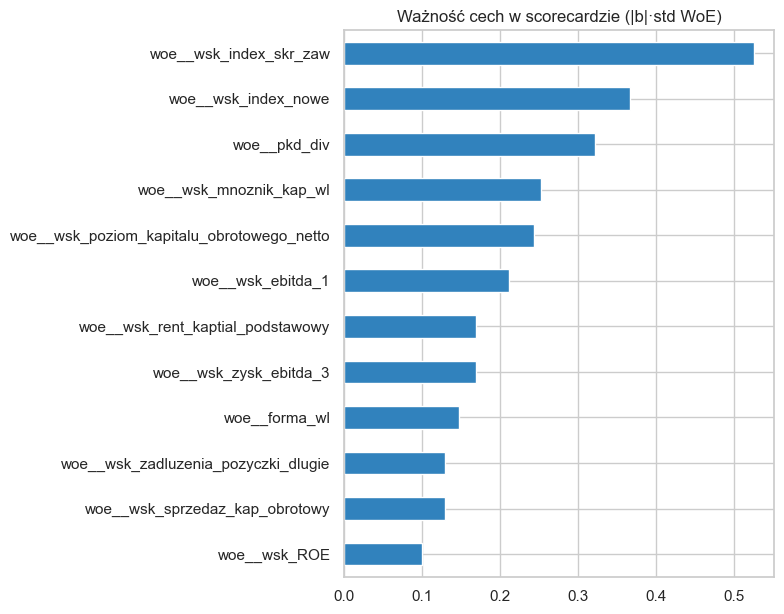

In [8]:
def raw_name(f):
    """Zamienia nazwę cechy WoE (np. 'woe__wsk_x') na nazwę surowej cechy ('wsk_x')."""
    return f.replace("woe__", "", 1)


feats_lr = clf_lr.features_
Wtr = prep_lr.transform(Xtr)[feats_lr]

# IV i kierunek dla każdej cechy z modelu (z tabeli IV z transformera)
iv_lista = []
kierunek_lista = []
for f in feats_lr:
    iv_lista.append(prep_lr.iv_table_.loc[raw_name(f), "IV"])
    kierunek_lista.append(prep_lr.iv_table_.loc[raw_name(f), "kierunek"])

coef_tab = pd.DataFrame({
    "współczynnik": clf_lr.coef_,
    "odds_ratio_na_1_WoE": np.exp(clf_lr.coef_),
    "std_WoE": Wtr.std().values,
    "ważność |b|·std": np.abs(clf_lr.coef_) * Wtr.std().values,
    "VIF": vif_series(Wtr).values,
    "IV": iv_lista,
    "kierunek (rosnąca wartość cechy)": kierunek_lista,
}, index=feats_lr)
coef_tab = coef_tab.sort_values("ważność |b|·std", ascending=False)
coef_tab["udział_ważności_%"] = 100 * coef_tab["ważność |b|·std"] / coef_tab["ważność |b|·std"].sum()

print(f"Wyraz wolny: {clf_lr.intercept_:.3f} | wszystkie współczynniki > 0: {bool((clf_lr.coef_ > 0).all())} | max VIF: {coef_tab['VIF'].max():.2f}")
display(coef_tab)

# wykres ważności cech
fig, ax = plt.subplots(figsize=(8, 0.4 * len(coef_tab) + 1.5))
coef_tab["ważność |b|·std"][::-1].plot.barh(ax=ax, color="#3182bd")
ax.set_title("Ważność cech w scorecardzie (|b|·std WoE)")
plt.tight_layout()
plt.savefig("figures/lr_importance.png", dpi=150)
plt.show()

**Znak vs kierunek zależności.** Kolumna „kierunek" mówi, jak zmienia się ryzyko wraz ze wzrostem wartości *oryginalnej* cechy (`inc`: rośnie, `dec`: maleje). Jest ona wyznaczana z danych (kierunek monotonicznego binningu), więc sama w sobie nie potwierdza sensu ekonomicznego, trzeba ją skonfrontować z oczekiwaniem.

In [9]:
# słowa kluczowe w nazwach wskaźników, które sugerują wyższe lub niższe ryzyko
RISK_UP = ["zadluz", "zobowiaz", "dzwigni", "koszt", "udzial_zob", "cykl", "zob_", "mnoznik", "kap_obcego", "zast_kapitalu_obcego"]
RISK_DOWN = ["rent", "roa", "roe", "ros", "marza", "ebit", "zysk", "plynnosc", "pokryci", "kapital_wlasn", "udzial_kap", "kapital_do_aktywa",
             "akt_generowania", "dni_istnienia", "log_aktywa", "struktura_kap_wlasnego", "zast_kapitalu_wlasnego", "zwrot"]


def zawiera_slowo(tekst, slowa):
    """Sprawdza, czy w tekście występuje którekolwiek ze słów z listy."""
    for s in slowa:
        if s in tekst:
            return True
    return False


def expected_direction(name):
    """Zgaduje (heurystycznie, po nazwie wskaźnika), czy ryzyko rośnie ('inc') czy maleje ('dec') wraz z wartością wskaźnika.
    Zwraca 'do oceny', gdy nie da się tego rozstrzygnąć."""
    n = name.lower()
    # wyjątki, które mają pierwszeństwo
    if zawiera_slowo(n, ["koszty_przychody", "koszt_dlugu"]):
        return "inc"
    up = zawiera_slowo(n, RISK_UP)
    down = zawiera_slowo(n, RISK_DOWN)
    if up and not down:
        return "inc"
    if down and not up:
        return "dec"
    return "do oceny"


# tylko cechy liczbowe (bez kategorii)
num_feats = []
for f in feats_lr:
    if raw_name(f) in NUM_INTERP:
        num_feats.append(raw_name(f))

obs_kier = []
ocz_kier = []
for f in num_feats:
    obs_kier.append(prep_lr.iv_table_.loc[f, "kierunek"])
    ocz_kier.append(expected_direction(f))

econ = pd.DataFrame({"obserwowany_kierunek": obs_kier,
                     "oczekiwany_(heurystyka)": ocz_kier},
                    index=num_feats)

# porównanie kierunku obserwowanego z oczekiwanym
zgodnosc = []
for f in econ.index:
    oczekiwany = econ.loc[f, "oczekiwany_(heurystyka)"]
    obserwowany = econ.loc[f, "obserwowany_kierunek"]
    if oczekiwany == "do oceny":
        zgodnosc.append("ręcznie")
    elif obserwowany == oczekiwany:
        zgodnosc.append("TAK")
    else:
        zgodnosc.append("NIE: sprawdź")
econ["zgodny?"] = zgodnosc
display(econ)

,obserwowany_kierunek,oczekiwany_(heurystyka),zgodny?
wsk_index_skr_zaw,inc,do oceny,ręcznie
wsk_index_nowe,inc,do oceny,ręcznie
wsk_mnoznik_kap_wl,inc,inc,TAK
wsk_poziom_kapitalu_obrotowego_netto,dec,do oceny,ręcznie
wsk_ebitda_1,dec,dec,TAK
wsk_ROE,dec,dec,TAK
wsk_rent_kaptial_podstawowy,dec,dec,TAK
wsk_sprzedaz_kap_obrotowy,dec,do oceny,ręcznie
wsk_zysk_ebitda_3,dec,dec,TAK
wsk_zadluzenia_pozyczki_dlugie,inc,inc,TAK


Pierwsze dwie zmienne nie zostały opisane w słowniku, ale zgodnie z informacjami z Internetu ich wyjaśnienie brzmi następująco:

wsk_index_skr_zaw (Wskaźnik indeksowy firm skreślonych i zawieszonych). Mierzy natężenie lub zmianę liczby podmiotów, które zostały wykreślone z rejestru (zakończyły działalność) oraz tych, które formalnie zawiesiły jej wykonywanie. Jest to kluczowy wskaźnik pogarszającej się koniunktury lub wzrostu ryzyka w danym sektorze.

wsk_index_nowe (Wskaźnik indeksowy firm nowych). Pokazuje poziom lub dynamikę nowo zarejestrowanych podmiotów gospodarczych w badanym okresie, co obrazuje napływ nowych przedsiębiorców na rynek."

Przy takiej definicji znak dodatni jest zgodny z oczekiwanym.

Wskaźnik poziomu kapitału obrotowego netto mierzy nadwyżkę aktywów obrotowych nad zobowiązaniami krótkoterminowymi i informuje o bezpieczeństwie finansowym firmy. Wyższy poziom tego wskaźnika co do zasady obniża ryzyko niewypłacalności (PD), ponieważ tworzy poduszkę gotówkową na spłatę bieżących długów

Wskaźnik sprzedaży kapitału obrotowego (rotacja kapitału obrotowego) mierzy, jak efektywnie firma wykorzystuje swoje środki obrotowe do generowania przychodów ze sprzedaży. Jego wzrost równiez powinien obniżać PD.

In [10]:
# Test monotoniczności poza próbą: biny z train zastosowane do VALIDATION
# (rzadkie defaulty => szum; patrzymy na zgodność znaku)
Zva = prep_lr.cleaner_.transform(Xva[prep_lr.num_cols])
rows = []
for f in num_feats:
    b = prep_lr.encoder_.bins_[f]
    v = Zva[f].values
    ok = ~np.isnan(v)
    bi = np.searchsorted(b["edges"], v[ok], side="right")
    t = pd.DataFrame({"bin": bi, "y": yva[ok]}).groupby("bin")["y"].mean()
    if len(t) > 2:
        rho = spearmanr(t.index, t.values)[0]
    else:
        rho = np.nan
    if b["direction"] == "inc":
        expected = 1
    else:
        expected = -1
    if np.isnan(rho):
        zgodny = None
    else:
        zgodny = bool(np.sign(rho) == expected)
    rows.append({"cecha": f, "n_binów": len(t), "spearman_bin_vs_default_val": rho, "zgodny_znak": zgodny})

mono_val = pd.DataFrame(rows).set_index("cecha")
display(mono_val)
print(f"Zgodny znak na walidacji: {mono_val['zgodny_znak'].mean():.0%} cech (na train monotoniczność jest wymuszona z konstrukcji).")

,n_binów,spearman_bin_vs_default_val,zgodny_znak
cecha,,,
wsk_index_skr_zaw,6,0.9429,True
wsk_index_nowe,8,0.5714,True
wsk_mnoznik_kap_wl,5,0.6000,True
wsk_poziom_kapitalu_obrotowego_netto,8,-0.5714,True
wsk_ebitda_1,8,-0.8095,True
wsk_ROE,3,-1.0000,True
wsk_rent_kaptial_podstawowy,6,-0.6000,True
wsk_sprzedaz_kap_obrotowy,4,-0.8000,True
wsk_zysk_ebitda_3,3,-0.5000,True


Zgodny znak na walidacji: 100% cech (na train monotoniczność jest wymuszona z konstrukcji).


### 1.2 Profile binów (punkty scorecardu) i PDP/ICE

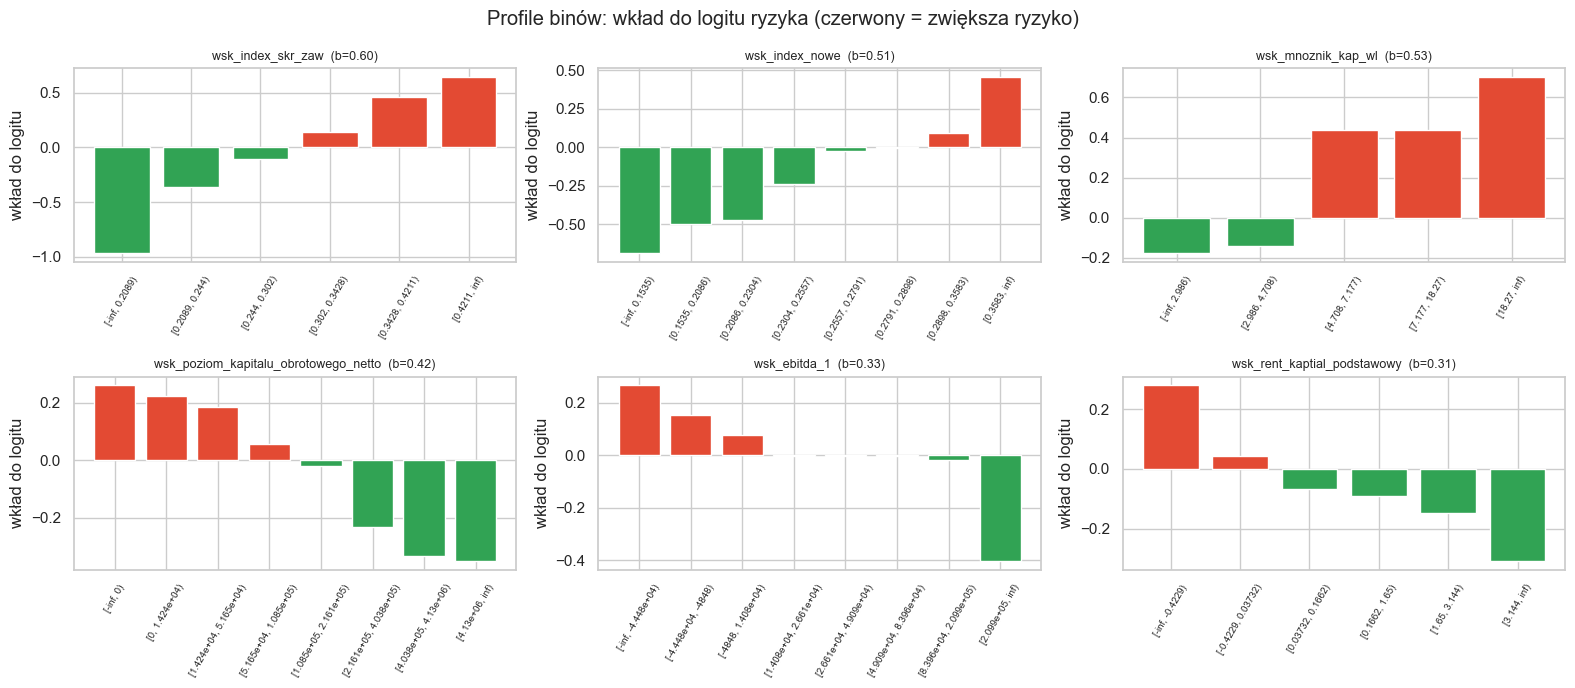

,bin,n,defaulty,default_rate,WoE,wkład_logit
0,"[-inf, 0.2089)",437,5,0.0114,-1.6196,-0.9657
1,"[0.2089, 0.244)",282,9,0.0319,-0.6147,-0.3666
2,"[0.244, 0.302)",359,18,0.0501,-0.1703,-0.1016
3,"[0.302, 0.3428)",353,26,0.0737,0.2309,0.1377
4,"[0.3428, 0.4211)",279,34,0.1219,0.7829,0.4668
5,"[0.4211, inf)",90,14,0.1556,1.0821,0.6452


In [11]:
# wkład binu do logitu = współczynnik · WoE(bin)  (dla najważniejszych cech liczbowych)
top_num = []
for f in coef_tab.index:
    if raw_name(f) in NUM_INTERP:
        top_num.append(f)
top_num = top_num[:6]

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, f in zip(axes.ravel(), top_num):
    profil = prep_lr.encoder_.profile(raw_name(f))
    b = coef_tab.loc[f, "współczynnik"]
    wklady = b * profil["WoE"]
    kolory = []
    for v in wklady:
        if v > 0:
            kolory.append("#e34a33")
        else:
            kolory.append("#31a354")
    ax.bar(range(len(profil)), wklady, color=kolory)
    ax.set_xticks(range(len(profil)))
    ax.set_xticklabels(profil["bin"], rotation=60, fontsize=7)
    ax.set_title(f"{raw_name(f)}  (b={b:.2f})", fontsize=9)
    ax.set_ylabel("wkład do logitu")
plt.suptitle("Profile binów: wkład do logitu ryzyka (czerwony = zwiększa ryzyko)")
plt.tight_layout()
plt.savefig("figures/lr_bin_profiles.png", dpi=150)
plt.show()

# tabela profilu dla najważniejszej cechy
profil_top = prep_lr.encoder_.profile(raw_name(top_num[0]))
profil_top["wkład_logit"] = coef_tab.loc[top_num[0], "współczynnik"] * profil_top["WoE"]
display(profil_top)

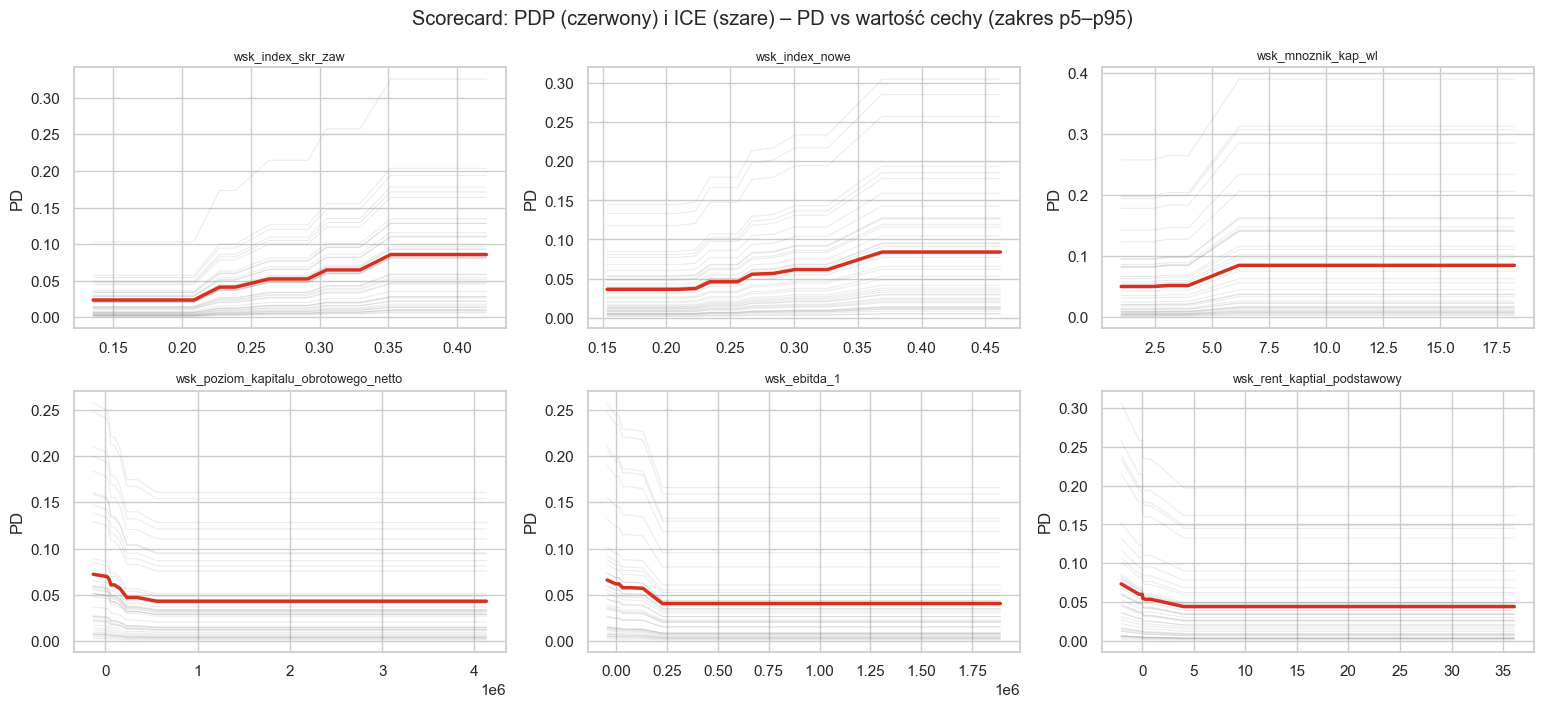

In [12]:
# PDP / ICE liczone ręcznie dla dowolnego pipeline'u (wejście = surowe cechy), więc to samo narzędzie posłuży dla black-box
def pdp_ice(pipe, X, feature, n_grid=15, n_ice=40, qlo=0.05, qhi=0.95, seed=SEED):
    """Liczy PDP (średnia PD) i ICE (PD pojedynczych obserwacji) dla jednej cechy.
    Wartości cechy: siatka kwantyli od qlo do qhi. Dla każdej wartości podstawiamy ją wszystkim wierszom X
    i liczymy predykcję pipeline'u. Zwraca (siatka, pdp, ice)."""
    s = X[feature].replace([np.inf, -np.inf], np.nan).dropna()
    grid = np.unique(np.quantile(s, np.linspace(qlo, qhi, n_grid)))

    # losujemy obserwacje do krzywych ICE
    rng = np.random.default_rng(seed)
    ice_rows = rng.choice(len(X), min(n_ice, len(X)), replace=False)

    pdp = []
    ice = np.zeros((len(ice_rows), len(grid)))
    for j in range(len(grid)):
        Xg = X.copy()
        Xg[feature] = grid[j]
        p = pipe.predict_proba(Xg)[:, 1]
        pdp.append(p.mean())
        ice[:, j] = p[ice_rows]
    return grid, np.array(pdp), ice


def plot_pdp(pipe, X, features, title, fname=None, ncols=3):
    """Rysuje wykresy PDP (czerwona linia) i ICE (szare linie) dla listy cech."""
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, f in zip(axes, features):
        g, pdp, ice = pdp_ice(pipe, X, f)
        ax.plot(g, ice.T, color="grey", alpha=.15, lw=.8)
        ax.plot(g, pdp, color="#d7301f", lw=2.5, label="PDP")
        ax.set_title(f, fontsize=9)
        ax.set_ylabel("PD")
    # puste osie wyłączamy
    for ax in axes[len(features):]:
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=150)
    plt.show()


pdp_feats = []
for f in top_num[:6]:
    pdp_feats.append(raw_name(f))
plot_pdp(pipe_lr, Xtr, pdp_feats, "Scorecard: PDP (czerwony) i ICE (szare) – PD vs wartość cechy (zakres p5–p95)", "figures/lr_pdp.png")

### 1.3 Interpretacja lokalna: dekompozycja logitu na wkłady cech

Dla scorecardu wyjaśnienie jest dokładne: logit(PD) = b₀ + Σ bⱼ·WoEⱼ. Wkład cechy względem „przeciętnego klienta” = bⱼ·(WoEⱼ(x) − średnie WoEⱼ w train); suma wkładów + logit przeciętnego klienta = logit(PD) obserwacji (tożsamość sprawdzamy).

In [13]:
W_mean = Wtr.mean()
logit_avg = clf_lr.intercept_ + float((clf_lr.coef_ * W_mean.values).sum())


def lr_contrib(X_rows):
    """Wkład każdej cechy scorecardu w logit predykcji względem przeciętnego klienta z train.
    Zwraca tabelę (wiersze = obserwacje, kolumny = cechy)."""
    W = prep_lr.transform(X_rows)[feats_lr]
    return (W - W_mean) * clf_lr.coef_


# sprawdzenie tożsamości na walidacji
C = lr_contrib(Xva)
recon = logit_avg + C.sum(axis=1).values
assert np.allclose(expit(recon), p_val_lr, atol=1e-8), "dekompozycja niezgodna z predykcją"
print("OK: wkłady cech sumują się dokładnie do logitu predykcji scorecardu.")

OK: wkłady cech sumują się dokładnie do logitu predykcji scorecardu.


### 1.4 Stabilność modelu interpretowalnego (CV)

In [14]:
# (a) stabilność metryk, patrz tabela CV powyżej; (b) stabilność selekcji i znaków współczynników w foldach
# ile razy każda cecha została wybrana w foldach
sel_freq_dict = {}
for f in feats_lr:
    licznik = 0
    for m in fold_models_lr:
        if f in m.features_:
            licznik = licznik + 1
    sel_freq_dict[f] = licznik
sel_freq = pd.Series(sel_freq_dict)

# współczynniki z poszczególnych foldów
lista_coef = []
for m in fold_models_lr:
    lista_coef.append(pd.Series(m.coef_, m.features_))
coefs_cv = pd.DataFrame(lista_coef).reindex(columns=feats_lr)

stab = pd.DataFrame({"wybrana_w_foldach": sel_freq,
                     "współczynnik_śr": coefs_cv.mean(),
                     "współczynnik_std": coefs_cv.std(),
                     "CV_współczynnika": coefs_cv.std() / coefs_cv.mean().abs()})
stab = stab.sort_values("wybrana_w_foldach", ascending=False)
display(stab)

# podobieństwo zbiorów cech między foldami (indeks Jaccarda)
sets = []
for m in fold_models_lr:
    sets.append(set(m.features_))
jaccardy = []
for a, b in combinations(sets, 2):
    jaccardy.append(len(a & b) / len(a | b))
jac = np.mean(jaccardy)

print(f"Średni Jaccard zbiorów cech między foldami: {jac:.2f} | cech wybranych w 5/5 foldów spośród końcowych: {(sel_freq == len(fold_models_lr)).sum()}/{len(feats_lr)}")
print("VIF (końcowy model), max:", round(coef_tab['VIF'].max(), 2), "| złożoność: liczba cech =", len(feats_lr), ", wszystkie ograniczone monotonicznie (biny) i ze znakiem dodatnim")

,wybrana_w_foldach,współczynnik_śr,współczynnik_std,CV_współczynnika
woe__wsk_index_skr_zaw,5,0.5773,0.0506,0.0877
woe__wsk_index_nowe,5,0.5038,0.0604,0.1198
woe__wsk_poziom_kapitalu_obrotowego_netto,5,0.4192,0.0992,0.2366
woe__pkd_div,4,0.5360,0.0362,0.0675
woe__wsk_zysk_ebitda_3,3,0.3979,0.0941,0.2365
woe__wsk_zadluzenia_pozyczki_dlugie,2,0.3766,0.0936,0.2486
woe__wsk_ROE,2,0.3481,0.2386,0.6854
woe__wsk_rent_kaptial_podstawowy,2,0.3351,0.0411,0.1227
woe__forma_wl,2,0.5269,0.0046,0.0086
woe__wsk_sprzedaz_kap_obrotowy,1,0.3571,NaN,NaN


Średni Jaccard zbiorów cech między foldami: 0.32 | cech wybranych w 5/5 foldów spośród końcowych: 3/12
VIF (końcowy model), max: 3.0 | złożoność: liczba cech = 12 , wszystkie ograniczone monotonicznie (biny) i ze znakiem dodatnim


## 2. Model black-box (3.4): LightGBM

* Wejście: ScoringFeatureBuilder(mode="blackbox"): wskaźniki, kwoty w signed_log1p, kategorie jako one-hot, winsoryzacja i imputacja mediany (parametry z foldu treningowego).
* Brak oversamplingu i scale_pos_weight, prawdopodobieństwa nie są sztucznie przesuwane (ważne dla kalibracji w sekcji 5).
* Tuning: Random Search (40 konfiguracji) w tym samym Stratified 5-fold CV co model interpretowalny; kryterium = średni log-loss w CV (miara wrażliwa na jakość prawdopodobieństw). Kontrola overfittingu: silna regularyzacja w przestrzeni poszukiwań (małe drzewa, duże min_child_samples, L1/L2, subsampling), reguła 1-SE (najprostszy model w obrębie błędu standardowego od najlepszego) oraz raport różnicy AUC train vs CV vs validation.

In [15]:
N_ITER = 40
N_JOBS = 2
folds_bb = prep_folds(FB_BB)

# przestrzeń przeszukiwania hiperparametrów (Random Search)
space = {"n_estimators": randint(100, 501),
         "learning_rate": loguniform(0.01, 0.1),
         "num_leaves": randint(4, 25),
         "max_depth": [-1, 3, 4, 5],
         "min_child_samples": randint(20, 81),
         "subsample": uniform(0.6, 0.4),
         "colsample_bytree": uniform(0.4, 0.6),
         "reg_lambda": loguniform(0.1, 50),
         "reg_alpha": loguniform(1e-3, 5)}
cands = list(ParameterSampler(space, n_iter=N_ITER, random_state=SEED))


def mk_lgb(params):
    """Tworzy model LightGBM z podanymi hiperparametrami (reszta ustawień stała, żeby wyniki były powtarzalne)."""
    return lgb.LGBMClassifier(**params, subsample_freq=1, random_state=SEED, n_jobs=N_JOBS, verbose=-1)


rows = []
for k in range(len(cands)):
    c = cands[k]
    ll = []
    auc = []
    auc_tr = []
    for Xa, ya, Xb, yb, _, _ in folds_bb:
        m = mk_lgb(c).fit(Xa, ya)
        p = m.predict_proba(Xb)[:, 1]
        ll.append(log_loss(yb, p))
        auc.append(roc_auc_score(yb, p))
        auc_tr.append(roc_auc_score(ya, m.predict_proba(Xa)[:, 1]))
    wiersz = {"id": k}
    wiersz.update(c)
    wiersz["logloss"] = np.mean(ll)
    wiersz["logloss_se"] = np.std(ll, ddof=1) / np.sqrt(len(ll))
    wiersz["auc_cv"] = np.mean(auc)
    wiersz["auc_std"] = np.std(auc, ddof=1)
    wiersz["auc_train"] = np.mean(auc_tr)
    rows.append(wiersz)

cv_bb = pd.DataFrame(rows).sort_values("logloss").reset_index(drop=True)
cv_bb["gap_auc_train_cv"] = cv_bb["auc_train"] - cv_bb["auc_cv"]
cv_bb["zlozonosc"] = cv_bb["n_estimators"] * cv_bb["num_leaves"]

# reguła 1-SE: wśród modeli z log-lossem w obrębie 1 błędu standardowego od najlepszego bierzemy najprostszy
b0 = cv_bb.iloc[0]
mieszczace_sie = cv_bb[cv_bb.logloss <= b0.logloss + b0.logloss_se]
pick = mieszczace_sie.sort_values("zlozonosc").iloc[0]

PARAM_KEYS = list(space.keys())
BEST_BB = {}
for k in PARAM_KEYS:
    if k in ["n_estimators", "num_leaves", "max_depth", "min_child_samples"]:
        BEST_BB[k] = int(pick[k])
    else:
        BEST_BB[k] = float(pick[k])

display(cv_bb[["id", "logloss", "logloss_se", "auc_cv", "auc_std", "auc_train", "gap_auc_train_cv",
               "n_estimators", "num_leaves", "learning_rate", "min_child_samples"]].head(8))
print("Wybrane hiperparametry (reguła 1-SE):", BEST_BB)

,id,logloss,logloss_se,auc_cv,auc_std,auc_train,gap_auc_train_cv,n_estimators,num_leaves,learning_rate,min_child_samples
0,39,0.1992,0.0077,0.7630,0.0608,0.9573,0.1944,243,16,0.0501,71
1,23,0.1995,0.0088,0.7625,0.0659,0.9611,0.1986,459,4,0.0250,37
2,38,0.1998,0.0057,0.7576,0.0604,0.9397,0.1821,207,8,0.0333,79
3,1,0.1999,0.0064,0.7588,0.0516,0.9744,0.2156,249,24,0.0399,22
4,36,0.2004,0.0054,0.7544,0.0551,0.9575,0.2031,241,15,0.0118,35
5,18,0.2007,0.0075,0.7540,0.0655,0.9536,0.1997,151,15,0.0253,68
6,32,0.2007,0.0079,0.7534,0.0564,0.9579,0.2044,198,4,0.0268,50
7,31,0.2008,0.0056,0.7530,0.0600,0.9699,0.2169,271,17,0.0106,36


Wybrane hiperparametry (reguła 1-SE): {'n_estimators': 134, 'learning_rate': 0.053654503243520245, 'num_leaves': 4, 'max_depth': 5, 'min_child_samples': 41, 'subsample': 0.9395655297064336, 'colsample_bytree': 0.5951099932160482, 'reg_lambda': 41.93935995317989, 'reg_alpha': 0.026087653866092905}


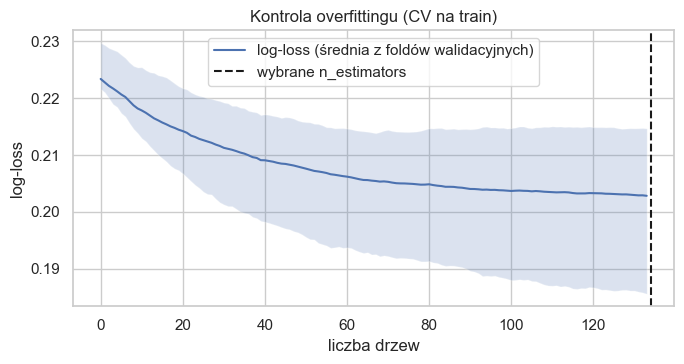

Minimum krzywej przy 134 drzewach; wybrano 134.


In [16]:
# diagnostyka overfittingu: krzywa log-lossu na foldach walidacyjnych w funkcji liczby drzew (dla wybranych hiperparametrów)
curves = []
for Xa, ya, Xb, yb, _, _ in folds_bb:
    m = mk_lgb(BEST_BB).fit(Xa, ya, eval_set=[(Xb, yb)])
    curves.append(np.array(m.evals_result_["valid_0"]["binary_logloss"]))
curves = np.array(curves)
mean_c = curves.mean(0)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(mean_c, label="log-loss (średnia z foldów walidacyjnych)")
ax.fill_between(range(len(mean_c)), curves.min(0), curves.max(0), alpha=.2)
ax.axvline(BEST_BB["n_estimators"], color="k", ls="--", label="wybrane n_estimators")
ax.set_xlabel("liczba drzew")
ax.set_ylabel("log-loss")
ax.legend()
ax.set_title("Kontrola overfittingu (CV na train)")
plt.tight_layout()
plt.savefig("figures/bb_overfit_curve.png", dpi=150)
plt.show()
print(f"Minimum krzywej przy {int(mean_c.argmin()) + 1} drzewach; wybrano {BEST_BB['n_estimators']}.")

In [17]:
# model końcowy LightGBM na całym train
pipe_bb = Pipeline([("prep", ScoringFeatureBuilder(**FB_BB)), ("clf", mk_lgb(BEST_BB))])
pipe_bb.fit(Xtr, ytr)
prep_bb = pipe_bb.named_steps["prep"]
bb_model = pipe_bb.named_steps["clf"]

# predykcje out-of-fold (CV) na train
oof_bb = pd.Series(index=idx_train, dtype=float)
cv_rows_bb = []
for Xa, ya, Xb, yb, tr, va in folds_bb:
    m = mk_lgb(BEST_BB).fit(Xa, ya)
    p = m.predict_proba(Xb)[:, 1]
    oof_bb.loc[va] = p
    cv_rows_bb.append(all_metrics(yb, p))

# predykcje na walidacji i na train (in-sample)
p_val_bb = pipe_bb.predict_proba(Xva)[:, 1]
p_tr_bb = pipe_bb.predict_proba(Xtr)[:, 1]

print("LightGBM – CV (5 foldów):")
display(summarize_cv(cv_rows_bb)[METRYKI].round(4))

tabela_bb = pd.DataFrame({"train (in-sample)": all_metrics(ytr, p_tr_bb),
                          "OOF-CV (train)": all_metrics(ytr, oof_bb.loc[idx_train].values),
                          "validation": all_metrics(yva, p_val_bb)})
display(tabela_bb.T[METRYKI + ["obs_rate"]])
print(f"Liczba cech wejściowych: {len(prep_bb.feature_names_)}")

LightGBM – CV (5 foldów):


,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD
średnia,0.7458,0.1865,0.4338,0.2028,0.0528,0.0434,1.1524,0.0567
odch.std,0.0625,0.0639,0.1192,0.0118,0.0020,0.0586,0.5046,0.0022
min,0.6939,0.1269,0.3082,0.1856,0.0499,-0.0349,0.7769,0.0545
max,0.8382,0.2937,0.5655,0.2147,0.0552,0.1263,1.9874,0.0602


,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD,obs_rate
train (in-sample),0.8853,0.4410,0.5946,0.1709,0.0470,0.0236,2.1101,0.0577,0.0589
OOF-CV (train),0.7411,0.1540,0.3817,0.2028,0.0528,0.0429,1.0508,0.0567,0.0589
validation,0.7513,0.2696,0.3712,0.1994,0.0517,0.0613,1.1787,0.0568,0.0600


Liczba cech wejściowych: 237


### 2.1 Wyjaśnialność globalna: SHAP (summary, beeswarm, dependence)
Wyjaśnienia liczymy na zbiorze walidacyjnym. Wartości SHAP są w skali log-odds.

,mean|SHAP| (log-odds)
wsk_index_nowe,0.2822
wsk_index_skr_zaw,0.2647
slog_Kapital_wlasny,0.2253
wsk_zysk_ebitda_3,0.0808
wsk_poziom_kapitalu_obrotowego_netto,0.0721
slog_zysk_sprzedazy,0.0645
wsk_struktura_kap_wlasnego_s_2,0.0508
wsk_sprzedaz_kap_obrotowy,0.0375
wsk_zadluzenie_kap_wlasnego,0.0360
wsk_ebitda_zobowiazan_odsetki_4,0.0357


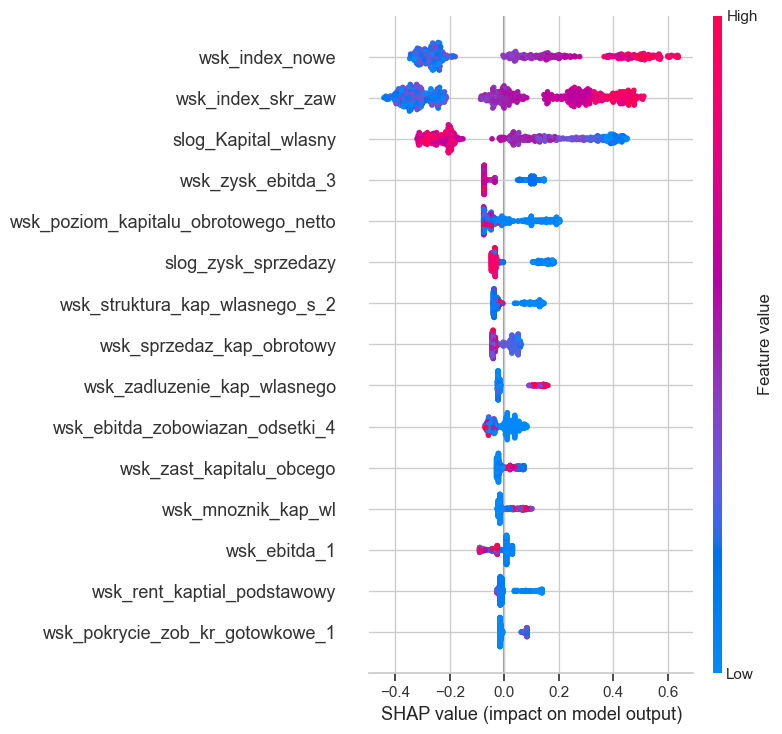

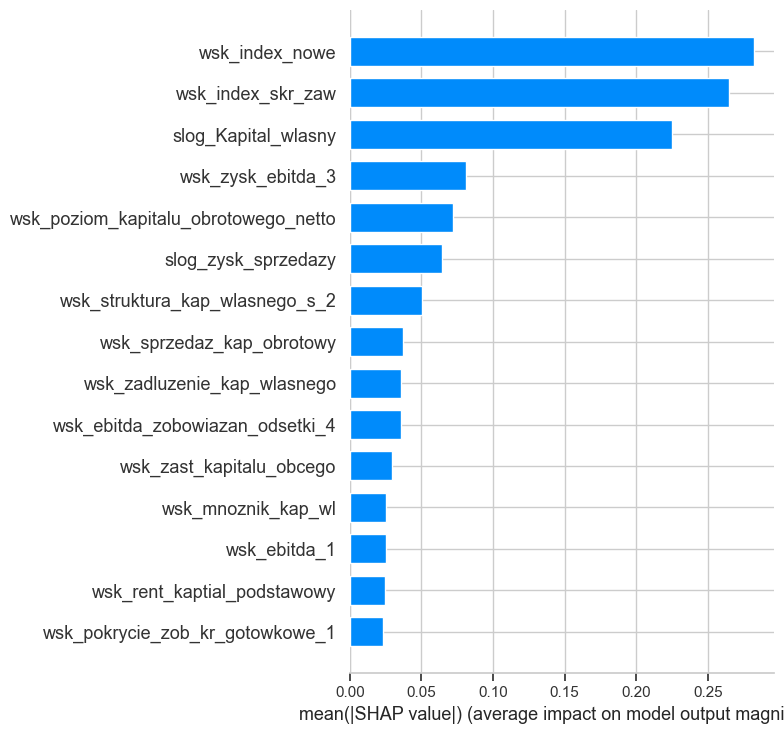

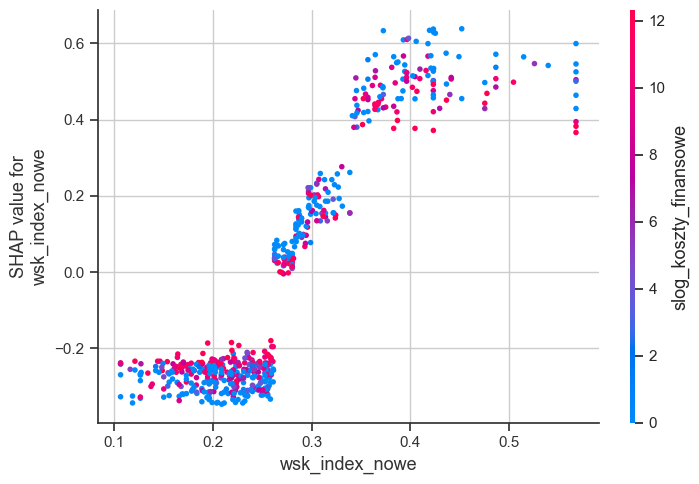

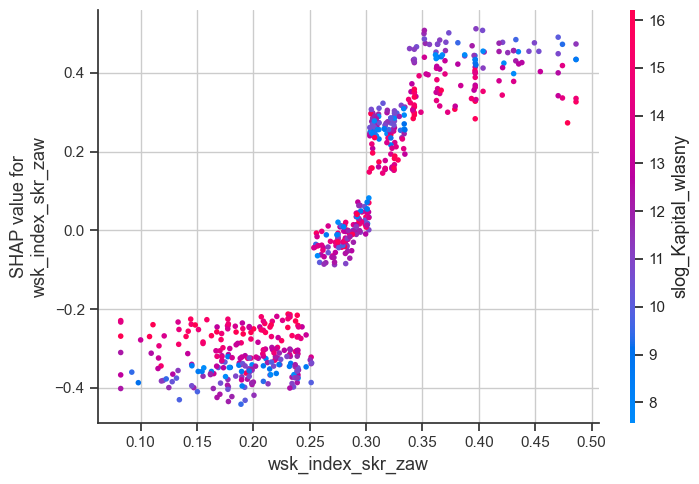

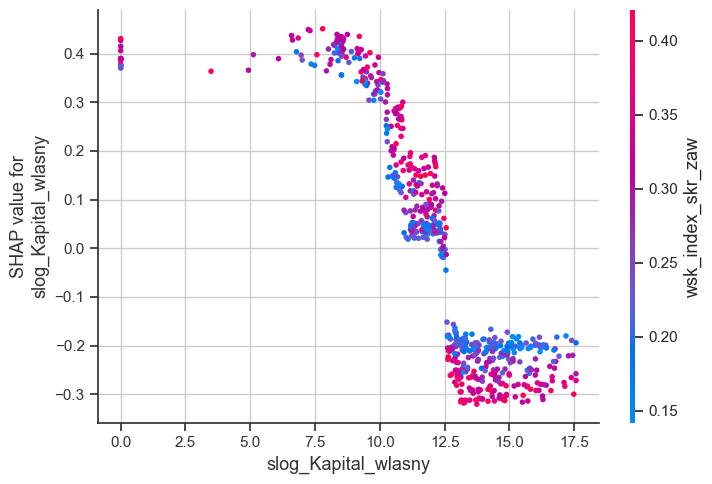

In [18]:
Xbb_tr = prep_bb.transform(Xtr)
Xbb_va = prep_bb.transform(Xva)
bb_cols = list(Xbb_tr.columns)
explainer = shap.TreeExplainer(bb_model)


def shap_pos(expl, X):
    """Liczy wartości SHAP dla klasy 'default' (pozytywnej). Różne wersje shap zwracają różne kształty wyniku,
    więc tu sprowadzamy je do jednej macierzy (obserwacje x cechy). Zwraca (macierz SHAP, wartość bazowa)."""
    sv = expl.shap_values(X)
    if isinstance(sv, list):
        sv = sv[-1]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        sv = sv[:, :, -1]
    ev = float(np.atleast_1d(expl.expected_value)[-1])
    return sv, ev


sv_va, ev_va = shap_pos(explainer, Xbb_va)
imp_shap = pd.Series(np.abs(sv_va).mean(0), index=bb_cols).sort_values(ascending=False)
display(imp_shap.head(15).to_frame("mean|SHAP| (log-odds)"))

shap.summary_plot(sv_va, Xbb_va, max_display=15, show=False)
plt.tight_layout()
plt.savefig("figures/shap_beeswarm.png", dpi=150)
plt.show()

shap.summary_plot(sv_va, Xbb_va, plot_type="bar", max_display=15, show=False)
plt.tight_layout()
plt.savefig("figures/shap_bar.png", dpi=150)
plt.show()

# wykresy zależności dla 3 najważniejszych cech
for f in imp_shap.index[:3]:
    shap.dependence_plot(f, sv_va, Xbb_va, show=False)
    plt.tight_layout()
    plt.savefig(f"figures/shap_dep_{f}.png", dpi=150)
    plt.show()

### 2.2 PDP/ICE black-boxa oraz porównanie z modelem interpretowalnym

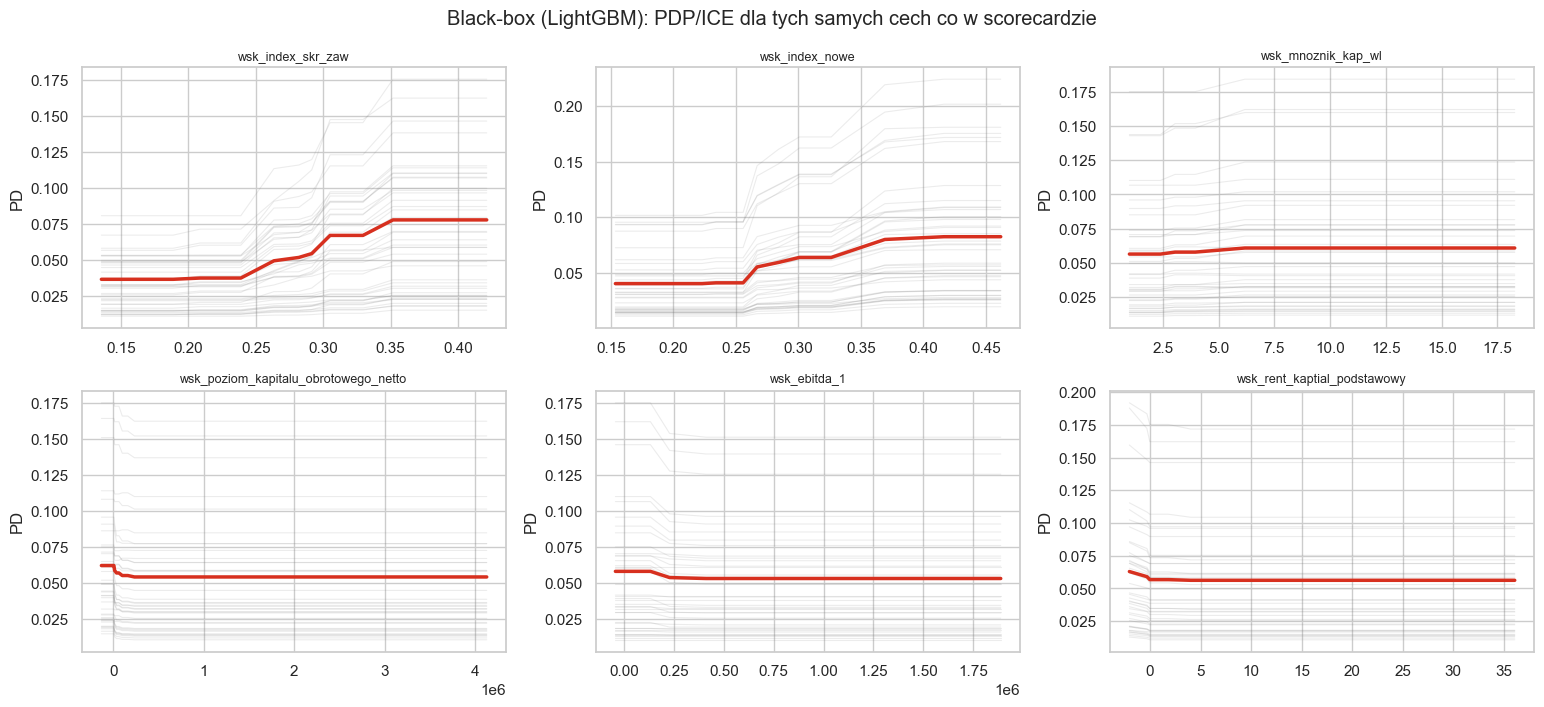

In [19]:
# te same cechy co w scorecardzie (o ile są w macierzy black-box)
common_pdp = []
for f in pdp_feats:
    if f in NUM_BLACK:
        common_pdp.append(f)
plot_pdp(pipe_bb, Xtr, common_pdp, "Black-box (LightGBM): PDP/ICE dla tych samych cech co w scorecardzie", "figures/bb_pdp.png")

In [20]:
# porównanie globalnych rankingów ważności: scorecard (|b|·std) vs SHAP (mean|SHAP|)
# – na cechach scorecardu obecnych w macierzy black-box
lr_imp = coef_tab["ważność |b|·std"].copy()
lr_imp.index = [raw_name(f) for f in lr_imp.index]

common = []
for f in lr_imp.index:
    if f in imp_shap.index:
        common.append(f)

cmp_imp = pd.DataFrame({"scorecard_ważność": lr_imp.loc[common], "SHAP_ważność": imp_shap.loc[common]})
cmp_imp["ranga_scorecard"] = cmp_imp["scorecard_ważność"].rank(ascending=False)
cmp_imp["ranga_SHAP"] = cmp_imp["SHAP_ważność"].rank(ascending=False)
display(cmp_imp.sort_values("ranga_scorecard"))

rho = spearmanr(cmp_imp["ranga_scorecard"], cmp_imp["ranga_SHAP"])[0]

# indeks Jaccarda dla Top-5 obu rankingów
top_k = 5
top_lr = set(lr_imp.head(top_k).index)
top_shap = set(imp_shap.head(top_k).index)
jacc = len(top_lr & top_shap) / len(top_lr | top_shap)

print(f"Spearman rang (cechy scorecardu obecne w obu modelach, n={len(common)}): {rho:.2f} | Jaccard Top-{top_k} scorecard vs SHAP: {jacc:.2f}")
print("Top-5 SHAP:", imp_shap.head(5).index.tolist())
print("Top-5 scorecard:", lr_imp.head(5).index.tolist())

,scorecard_ważność,SHAP_ważność,ranga_scorecard,ranga_SHAP
wsk_index_skr_zaw,0.5248,0.2647,1.0000,2.0000
wsk_index_nowe,0.3660,0.2822,2.0000,1.0000
wsk_mnoznik_kap_wl,0.2530,0.0255,3.0000,6.0000
wsk_poziom_kapitalu_obrotowego_netto,0.2433,0.0721,4.0000,4.0000
wsk_ebitda_1,0.2120,0.0251,5.0000,7.0000
wsk_rent_kaptial_podstawowy,0.1694,0.0245,6.0000,8.0000
wsk_zysk_ebitda_3,0.1691,0.0808,7.0000,3.0000
wsk_zadluzenia_pozyczki_dlugie,0.1297,0.0000,8.0000,9.5000
wsk_sprzedaz_kap_obrotowy,0.1295,0.0375,9.0000,5.0000
wsk_ROE,0.0998,0.0000,10.0000,9.5000


Spearman rang (cechy scorecardu obecne w obu modelach, n=10): 0.67 | Jaccard Top-5 scorecard vs SHAP: 0.43
Top-5 SHAP: ['wsk_index_nowe', 'wsk_index_skr_zaw', 'slog_Kapital_wlasny', 'wsk_zysk_ebitda_3', 'wsk_poziom_kapitalu_obrotowego_netto']
Top-5 scorecard: ['wsk_index_skr_zaw', 'wsk_index_nowe', 'pkd_div', 'wsk_mnoznik_kap_wl', 'wsk_poziom_kapitalu_obrotowego_netto']


### 2.3 Interpretacja lokalna: studia przypadków (walidacja)

Wybieramy 4 obserwacje: (1) *default o najwyższym PD*, (2) *dobry klient o najniższym PD*, (3) *przypadek graniczny*, obserwacja o PD z okolic 85. percentyla i (4) *niewykryty default* (default o najniższym PD z black-boxa). Dla każdej: wyjaśnienie bezpośrednie scorecardu, SHAP i LIME.

In [21]:
yv = yva
pv_b = p_val_bb
pv_l = p_val_lr
q85 = np.quantile(pv_b, 0.85)

# pozycje obserwacji w zbiorze walidacyjnym
poz_default = np.where(yv == 1)[0]
poz_dobry = np.where(yv == 0)[0]

cases = {}
cases["1. wykryty default"] = int(poz_default[np.argmax(pv_b[yv == 1])])
cases["2. pewny dobry klient"] = int(poz_dobry[np.argmin(pv_b[yv == 0])])
cases["3. przypadek graniczny"] = int(np.argmin(np.abs(pv_b - q85)))
cases["4. niewykryty default"] = int(poz_default[np.argmin(pv_b[yv == 1])])


def predict_fn(a):
    """Funkcja predykcji dla LIME: przyjmuje tablicę numpy i zwraca prawdopodobieństwa klas z modelu LightGBM."""
    return bb_model.predict_proba(pd.DataFrame(a, columns=bb_cols))


# kolumny binarne (0/1) traktujemy w LIME jako kategoryczne
bin_idx = []
for i in range(len(bb_cols)):
    c = bb_cols[i]
    if set(np.unique(Xbb_tr[c])) <= {0, 1}:
        bin_idx.append(i)


def make_lime(seed):
    """Tworzy obiekt LIME (dla danych tabelarycznych) z zadanym ziarnem."""
    return LimeTabularExplainer(Xbb_tr.values, feature_names=bb_cols, class_names=["non-default", "default"],
                                mode="classification", categorical_features=bin_idx,
                                discretize_continuous=True, random_state=seed)


def lime_score(e):
    """Zwraca lokalne R^2 modelu zastępczego LIME."""
    s = e.score
    if isinstance(s, dict):
        return float(s[1])
    return float(s)


def lime_local_pred(e):
    """Zwraca predykcję lokalnego modelu LIME."""
    lp = e.local_pred
    if isinstance(lp, dict):
        lp = lp[1]
    return float(np.atleast_1d(lp)[0])


def lime_explain(i, seed=0, k=10, n=5000):
    """Wyjaśnia metodą LIME obserwację o pozycji i (w zbiorze walidacyjnym): k cech, n próbek losowych."""
    explainer_lime = make_lime(seed)
    return explainer_lime.explain_instance(Xbb_va.iloc[i].values, predict_fn, num_features=k, num_samples=n)


def top_cech(seria, k):
    """Zwraca tekst z k cechami o największej wartości bezwzględnej wkładu, np. 'cecha (+0.35), ...'."""
    kolejnosc = seria.abs().sort_values(ascending=False).index
    posortowana = seria.reindex(kolejnosc)
    kawalki = []
    for nazwa, wartosc in posortowana.head(k).items():
        kawalki.append(f"{nazwa} ({wartosc:+.2f})")
    return ", ".join(kawalki)


def case_table(name, i, k=5):
    """Wypisuje porównanie trzech wyjaśnień (scorecard, SHAP, LIME) dla jednej obserwacji walidacyjnej o pozycji i."""
    # scorecard: wkłady w logit
    c = lr_contrib(Xva.iloc[[i]]).iloc[0]
    c.index = [raw_name(f) for f in c.index]

    # LIME: wagi lokalne
    e = lime_explain(i, seed=SEED)
    wagi_lime = {}
    for j, w in e.local_exp[1]:
        wagi_lime[bb_cols[j]] = w
    lw = pd.Series(wagi_lime)

    # SHAP
    s = pd.Series(sv_va[i], index=bb_cols)

    print(f"=== {name} | y={yv[i]} | PD scorecard={pv_l[i]:.3f}, PD LightGBM={pv_b[i]:.3f} | LIME R^2={lime_score(e):.2f}")
    print("  scorecard (wkład w logit):", top_cech(c, k))
    print("  SHAP (log-odds):          ", top_cech(s, k))
    print("  LIME (waga lokalna):      ", top_cech(lw, k))
    print()


for name, i in cases.items():
    case_table(name, i)

=== 1. wykryty default | y=1 | PD scorecard=0.513, PD LightGBM=0.310 | LIME R^2=0.46
  scorecard (wkład w logit): wsk_index_skr_zaw (+0.65), pkd_div (+0.62), wsk_index_nowe (+0.57), wsk_zadluzenia_pozyczki_dlugie (+0.56), wsk_mnoznik_kap_wl (+0.50)
  SHAP (log-odds):           wsk_index_nowe (+0.52), wsk_index_skr_zaw (+0.48), slog_Kapital_wlasny (+0.20), slog_zysk_sprzedazy (+0.16), wsk_zadluzenie_kap_wlasnego (+0.14)
  LIME (waga lokalna):       wsk_index_nowe (+0.03), wsk_index_skr_zaw (+0.03), wsk_zadluzenie_kap_wlasnego (+0.01), slog_Zobowiazania_dostaw_uslug_pow12m_pozostale (-0.01), slog_zysk_sprzedazy (+0.01)

=== 2. pewny dobry klient | y=0 | PD scorecard=0.003, PD LightGBM=0.011 | LIME R^2=0.22
  scorecard (wkład w logit): wsk_index_skr_zaw (-0.79), wsk_index_nowe (-0.57), wsk_poziom_kapitalu_obrotowego_netto (-0.27), pkd_div (-0.16), wsk_zysk_ebitda_3 (-0.13)
  SHAP (log-odds):           wsk_index_skr_zaw (-0.27), wsk_index_nowe (-0.24), slog_Kapital_wlasny (-0.21), wsk_pozi

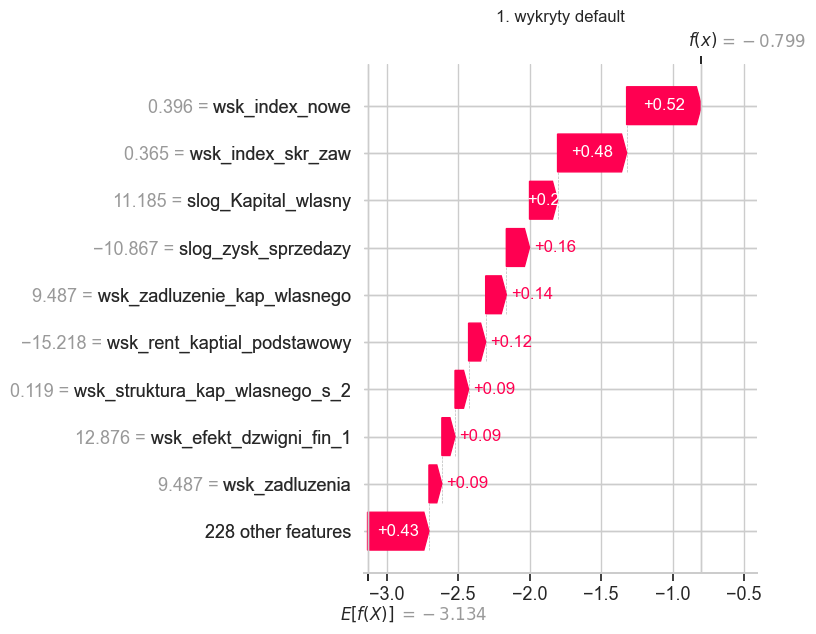

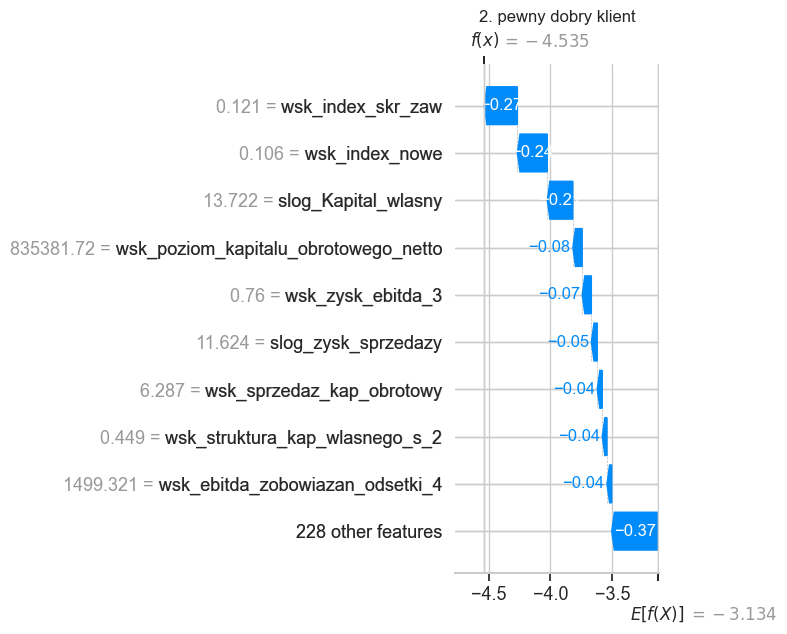

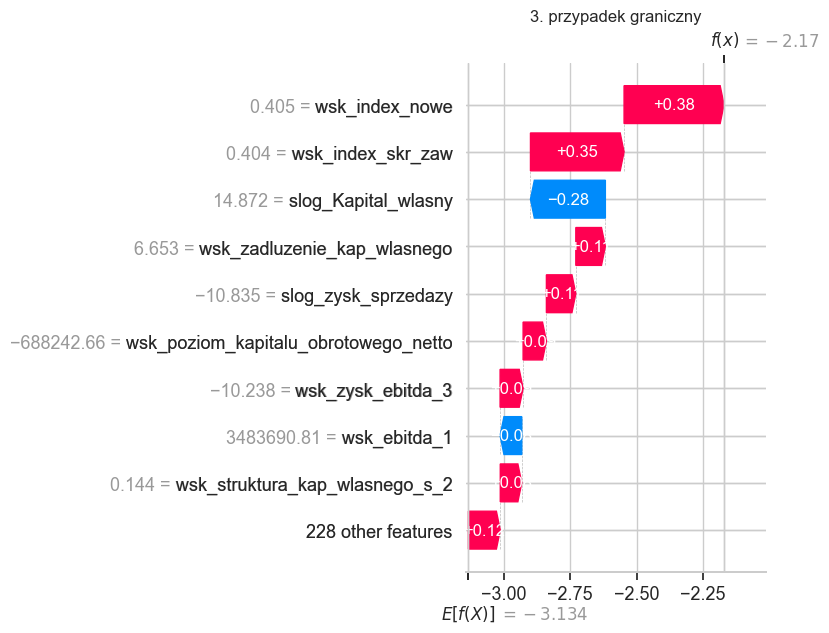

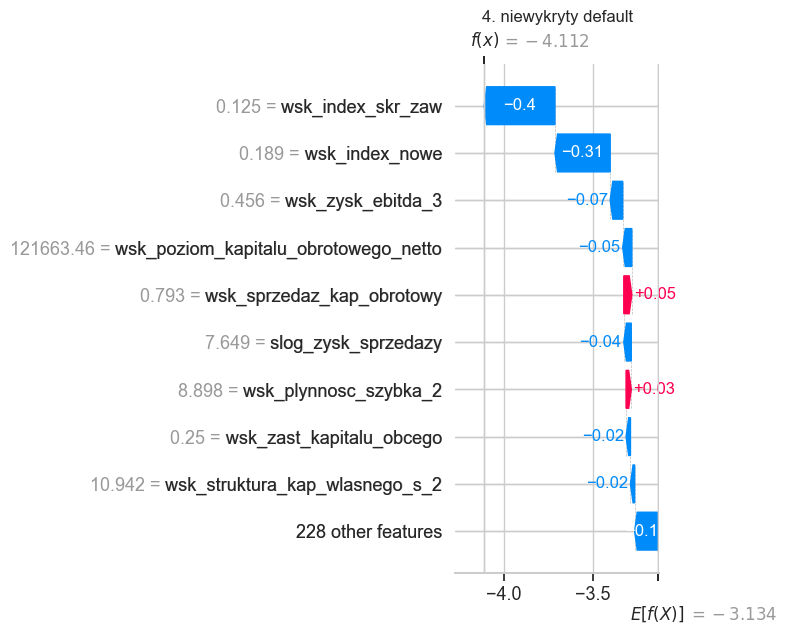

In [22]:
# wykresy SHAP waterfall dla przypadków
for name, i in cases.items():
    wyjasnienie = shap.Explanation(values=sv_va[i], base_values=ev_va, data=Xbb_va.iloc[i].values, feature_names=bb_cols)
    shap.plots.waterfall(wyjasnienie, max_display=10, show=False)
    plt.title(name)
    plt.tight_layout()
    plt.savefig(f"figures/shap_waterfall_{name[:1]}.png", dpi=150)
    plt.show()

### 2.4 What-if
Dla obserwacji z przypadku 1 (wykryty default): ustawiamy 3 najsilniej zwiększające ryzyko (wg SHAP) wskaźniki na medianę z train (pojedynczo i razem) i porównujemy reakcję obu modeli. Zmiany dotyczą surowych cech i przechodzą przez cały pipeline (binning/WoE, imputacja itd.).

In [23]:
i0 = cases["1. wykryty default"]

# 3 cechy (surowe wskaźniki) o największym dodatnim SHAP dla tej obserwacji
shap_posortowane = pd.Series(sv_va[i0], index=bb_cols).sort_values(ascending=False)
raw_feats = []
for f in shap_posortowane.index:
    if f in NUM_INTERP:
        raw_feats.append(f)
    if len(raw_feats) == 3:
        break

med = Xtr[raw_feats].replace([np.inf, -np.inf], np.nan).median()
base = Xva.iloc[[i0]]

# scenariusze: bez zmian, każda cecha osobno -> mediana, wszystkie trzy naraz -> mediana
scen = {"obserwacja (bez zmian)": {}}
for f in raw_feats:
    scen[f"{f} -> mediana"] = {f: med[f]}
wszystkie = {}
for f in raw_feats:
    wszystkie[f] = med[f]
scen["wszystkie 3 -> mediana"] = wszystkie

wi = []
for name, ch in scen.items():
    r = base.copy()
    for f, v in ch.items():
        r[f] = v
    wi.append({"scenariusz": name,
               "PD_scorecard": pipe_lr.predict_proba(r)[0, 1],
               "PD_LightGBM": pipe_bb.predict_proba(r)[0, 1]})
display(pd.DataFrame(wi))
print("Wartości obserwacji:", base[raw_feats].iloc[0].to_dict(), "| mediany train:", med.to_dict())

,scenariusz,PD_scorecard,PD_LightGBM
0,obserwacja (bez zmian),0.5134,0.3103
1,wsk_index_nowe -> mediana,0.3949,0.1629
2,wsk_index_skr_zaw -> mediana,0.3741,0.2124
3,wsk_zadluzenie_kap_wlasnego -> mediana,0.5134,0.2727
4,wszystkie 3 -> mediana,0.2699,0.0895


Wartości obserwacji: {'wsk_index_nowe': 0.3962252513415165, 'wsk_index_skr_zaw': 0.3653089166524046, 'wsk_zadluzenie_kap_wlasnego': 9.486889178743988} | mediany train: {'wsk_index_nowe': 0.25569526167116297, 'wsk_index_skr_zaw': 0.2819018762382008, 'wsk_zadluzenie_kap_wlasnego': 0.5140819628519139}


## 3. Wierność i stabilność wyjaśnień

### 3.1 Wierność (fidelity)
* **LIME:** lokalne R² modelu zastępczego (ważonego w otoczeniu obserwacji) oraz błąd |predykcja lokalnego modelu − predykcja black-boxa| dla 30 losowych obserwacji walidacyjnych.
* **SHAP:** sprawdzenie addytywności, wartość bazowa + Σ SHAP = surowy wynik (log-odds) modelu.
* **Scorecard:** wyjaśnienie bezpośrednie jest tożsame z modelem (sprawdzone w 1.3).

,i,R2_lokalne,PD_model,PD_lime,blad_abs
mean,322.6000,0.2574,0.0710,0.0718,0.0246
50%,315.5000,0.2283,0.0603,0.0798,0.0212
min,49.0000,0.0727,0.0130,0.0155,0.0001
max,588.0000,0.5847,0.2083,0.1440,0.0804


LIME: mediana lokalnego R^2 = 0.23; udział obserwacji z R^2<0.5: 97%; mediana błędu |ΔPD| = 0.021
SHAP – maks. błąd addytywności: 5.77e-15 (log-odds)


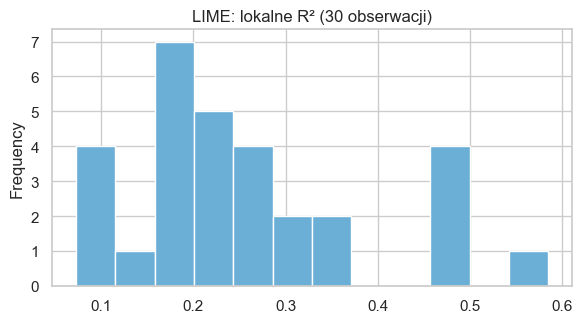

In [24]:
rng = np.random.default_rng(SEED)
sample_i = rng.choice(len(Xva), 30, replace=False)

fid = []
for i in sample_i:
    e = lime_explain(int(i), seed=SEED, k=10)
    lp = lime_local_pred(e)
    mp = float(np.asarray(e.predict_proba)[1])
    fid.append({"i": int(i), "R2_lokalne": lime_score(e), "PD_model": mp, "PD_lime": lp, "blad_abs": abs(lp - mp)})
fid = pd.DataFrame(fid)
display(fid.describe().loc[["mean", "50%", "min", "max"]])
print(f"LIME: mediana lokalnego R^2 = {fid.R2_lokalne.median():.2f}; udział obserwacji z R^2<0.5: {(fid.R2_lokalne < 0.5).mean():.0%}; mediana błędu |ΔPD| = {fid.blad_abs.median():.3f}")

# SHAP: sprawdzenie addytywności (wartość bazowa + suma SHAP = surowy wynik modelu)
raw_val = bb_model.predict(Xbb_va, raw_score=True)
add_err = np.abs(ev_va + sv_va.sum(1) - raw_val).max()
print(f"SHAP – maks. błąd addytywności: {add_err:.2e} (log-odds)")

fig, ax = plt.subplots(figsize=(6, 3.4))
fid.R2_lokalne.plot.hist(bins=12, ax=ax, color="#6baed6")
ax.set_title("LIME: lokalne R² (30 obserwacji)")
plt.tight_layout()
plt.savefig("figures/lime_fidelity.png", dpi=150)
plt.show()

### 3.2 Stabilność
Rozdzielamy trzy źródła niestabilności:
1. **metoda**: ta sama obserwacja i ten sam model, LIME z 10 różnymi seedami (Spearman wag, Jaccard Top-5, zgodność znaku),
2. **próbka objaśniana**: bootstrap wierszy walidacyjnych dla globalnego rankingu SHAP,
3. **model**: przetrenowanie LightGBM na 5 foldach treningowych i porównanie rankingów SHAP (na tym samym zbiorze walidacyjnym); dla porównania ten sam test dla współczynników scorecardu.

In [25]:
def lime_w(i, seed):
    """Zwraca wektor wag LIME (długość = liczba cech) dla obserwacji i; cechy spoza wyjaśnienia mają wagę 0."""
    e = lime_explain(i, seed=seed, k=10)
    w = np.zeros(len(bb_cols))
    for j, v in e.local_exp[1]:
        w[j] = v
    return w


def topk(w, k=5):
    """Zwraca zbiór indeksów k cech o największej wartości bezwzględnej wagi."""
    return set(np.argsort(-np.abs(w))[:k])


def pair_stats(W, k=5):
    """Dla macierzy wag (wiersz = jedno uruchomienie LIME) liczy po wszystkich parach uruchomień:
    średni Spearman wag oraz średni indeks Jaccarda zbiorów Top-k. Zwraca (spearman, jaccard)."""
    used = np.where((W != 0).any(0))[0]
    sp = []
    jc = []
    for a, b in combinations(range(len(W)), 2):
        sp.append(spearmanr(W[a, used], W[b, used])[0])
        top_a = topk(W[a], k)
        top_b = topk(W[b], k)
        jc.append(len(top_a & top_b) / len(top_a | top_b))
    return np.nanmean(sp), np.mean(jc)


seeds = list(range(10))
rows = []
for name, i in cases.items():
    # 10 uruchomień LIME z różnymi seedami
    lista_wag = []
    for s in seeds:
        lista_wag.append(lime_w(i, s))
    W = np.array(lista_wag)
    sp, jc = pair_stats(W)

    # zgodność znaku wag dla 3 najważniejszych cech
    top3 = list(np.argsort(-np.abs(W.mean(0)))[:3])
    zgodnosci = []
    for j in top3:
        zgodnosci.append(np.mean(np.sign(W[:, j]) == np.sign(np.median(W[:, j]))))
    same_sign = np.mean(zgodnosci)

    rows.append({"przypadek": name, "Spearman_wag": sp, "Jaccard_top5": jc, "zgodność_znaku_top3": same_sign})

lime_stab = pd.DataFrame(rows).set_index("przypadek")
display(lime_stab)

,Spearman_wag,Jaccard_top5,zgodność_znaku_top3
przypadek,,,
1. wykryty default,0.7602,0.7217,1.0000
2. pewny dobry klient,0.4935,0.4656,1.0000
3. przypadek graniczny,0.8705,0.7249,1.0000
4. niewykryty default,0.3870,0.4497,1.0000


In [26]:
# ============================================================
# STABILNOŚĆ WYJAŚNIEŃ SHAP
# ============================================================
K = 10   # ile najważniejszych cech porównujemy


def pairwise_rank_stats(M, k=10):
    """Porównuje rankingi ważności cech po wszystkich parach kolumn tabeli M.
    M: tabela (wiersze = cechy, kolumny = rankingi z różnych eksperymentów).
    Brak cechy w danym modelu oznacza importance = 0.
    Zwraca (średni Spearman, średni Jaccard Top-k)."""
    spearmans = []
    jaccards = []
    for a, b in combinations(M.columns, 2):
        x = M[a]
        y = M[b]
        rho = spearmanr(x, y)[0]
        if np.isfinite(rho):
            spearmans.append(rho)
        top_a = set(x.nlargest(k).index)
        top_b = set(y.nlargest(k).index)
        suma = top_a | top_b
        wspolne = top_a & top_b
        if len(suma) > 0:
            jaccards.append(len(wspolne) / len(suma))
        else:
            jaccards.append(np.nan)
    return float(np.nanmean(spearmans)), float(np.nanmean(jaccards))


# ------------------------------------------------------------
# 1. Bootstrap, ten sam model, różne próbki walidacyjne
# ------------------------------------------------------------
B = 200
rng_stab = np.random.default_rng(SEED)

# referencyjny ranking SHAP z całego validation
full_imp = pd.Series(np.abs(sv_va).mean(axis=0), index=bb_cols)
ref_top = set(full_imp.nlargest(K).index)

boot_spearman = []
boot_jaccard = []
boot_top_freq = pd.Series(0.0, index=bb_cols)

for b in range(B):
    # losowanie obserwacji ze zwracaniem
    sample_idx = rng_stab.integers(0, len(sv_va), size=len(sv_va))

    # globalna ważność SHAP w wylosowanej próbce
    imp = pd.Series(np.abs(sv_va[sample_idx]).mean(axis=0), index=bb_cols)

    # porównanie z rankingiem referencyjnym
    rho = spearmanr(full_imp.values, imp.values)[0]
    boot_spearman.append(rho)

    top_b = set(imp.nlargest(K).index)
    boot_jaccard.append(len(ref_top & top_b) / len(ref_top | top_b))
    boot_top_freq.loc[list(top_b)] += 1

boot_top_freq = boot_top_freq / B

boot_summary = {"Spearman_mean": np.mean(boot_spearman),
                "Spearman_5%": np.quantile(boot_spearman, 0.05),
                "Spearman_95%": np.quantile(boot_spearman, 0.95),
                "Jaccard_mean": np.mean(boot_jaccard),
                "Jaccard_5%": np.quantile(boot_jaccard, 0.05),
                "Jaccard_95%": np.quantile(boot_jaccard, 0.95)}

print("BOOTSTRAP SHAP – stabilność rankingu dla tego samego modelu")
display(pd.Series(boot_summary).to_frame("Wynik"))
print("Najczęściej występujące cechy w Top-10 podczas bootstrapu:")
display(boot_top_freq.sort_values(ascending=False).head(15).to_frame("Częstość w Top-10"))

# ------------------------------------------------------------
# 2. Refit, nowy preprocessing i nowy model w każdym foldzie
# ------------------------------------------------------------
refit_importances = []

for fold_id, (tr, va) in enumerate(cv_train, start=1):
    # nowy preprocessing dopasowany WYŁĄCZNIE na foldzie treningowym
    prep_fold = ScoringFeatureBuilder(**FB_BB).fit(df.iloc[tr], y_all[tr])
    X_fold_tr = prep_fold.transform(df.iloc[tr])
    X_ref = prep_fold.transform(Xva)

    # nowy model LightGBM (hiperparametry stałe – badamy wpływ próby i preprocessingu)
    model_fold = mk_lgb(BEST_BB).fit(X_fold_tr, y_all[tr])

    # SHAP na tym samym zbiorze validation
    explainer_fold = shap.TreeExplainer(model_fold)
    sv_fold, _ = shap_pos(explainer_fold, X_ref)

    # globalna ważność cech dla tego modelu
    imp_fold = pd.Series(np.abs(sv_fold).mean(axis=0), index=X_ref.columns, name=f"fold_{fold_id}")
    refit_importances.append(imp_fold)

# wspólny zestaw cech – brakująca cecha dostaje importance = 0
refit_matrix = pd.concat(refit_importances, axis=1).fillna(0.0)
refit_spearman, refit_jaccard = pairwise_rank_stats(refit_matrix, k=K)

# jak często cecha trafia do Top-10 w poszczególnych modelach
fold_top_freq = pd.Series(0.0, index=refit_matrix.index)
for col in refit_matrix.columns:
    top = refit_matrix[col].nlargest(K).index
    fold_top_freq.loc[list(top)] += 1 / len(refit_matrix.columns)

print("REFIT SHAP – stabilność między foldami")
print(f"Średni Spearman: {refit_spearman:.4f}")
print(f"Średni Jaccard Top-{K}: {refit_jaccard:.4f}")
print("Najczęściej występujące cechy w Top-10 między foldami:")
display(fold_top_freq.sort_values(ascending=False).head(15).to_frame("Częstość w Top-10"))

# ------------------------------------------------------------
# 3. Stabilność modelu interpretowalnego, scorecard
# ------------------------------------------------------------
lr_cv_imp = []
for k in range(len(fold_models_lr)):
    model_fold = fold_models_lr[k]
    Xa = folds_woe[k][0]
    waznosc = np.abs(model_fold.coef_.ravel()) * Xa[model_fold.features_].std().values
    nazwy = [raw_name(f) for f in model_fold.features_]
    lr_cv_imp.append(pd.Series(waznosc, index=nazwy))

lr_matrix = pd.concat(lr_cv_imp, axis=1).fillna(0.0)
lr_spearman, lr_jaccard = pairwise_rank_stats(lr_matrix, k=K)

# ------------------------------------------------------------
# 4. Zbiorcze porównanie
# ------------------------------------------------------------
stab_tab = pd.DataFrame([
    {"eksperyment": "SHAP – bootstrap, ten sam model", "Spearman": np.mean(boot_spearman), "Jaccard Top-10": np.mean(boot_jaccard)},
    {"eksperyment": "SHAP – refit z preprocessingiem w foldach", "Spearman": refit_spearman, "Jaccard Top-10": refit_jaccard},
    {"eksperyment": "Scorecard – refit między foldami", "Spearman": lr_spearman, "Jaccard Top-10": lr_jaccard},
]).set_index("eksperyment")
display(stab_tab)

print(f"LIME – zmiana seedu: średni Spearman wag = {lime_stab.Spearman_wag.mean():.2f}, Jaccard Top-5 = {lime_stab.Jaccard_top5.mean():.2f}")

BOOTSTRAP SHAP – stabilność rankingu dla tego samego modelu


,Wynik
Spearman_mean,0.9999
Spearman_5%,0.9999
Spearman_95%,1.0000
Jaccard_mean,1.0000
Jaccard_5%,1.0000
Jaccard_95%,1.0000


Najczęściej występujące cechy w Top-10 podczas bootstrapu:


,Częstość w Top-10
wsk_index_skr_zaw,1.0000
wsk_index_nowe,1.0000
wsk_sprzedaz_kap_obrotowy,1.0000
wsk_ebitda_zobowiazan_odsetki_4,1.0000
wsk_zadluzenie_kap_wlasnego,1.0000
wsk_poziom_kapitalu_obrotowego_netto,1.0000
slog_Kapital_wlasny,1.0000
wsk_struktura_kap_wlasnego_s_2,1.0000
wsk_zysk_ebitda_3,1.0000
slog_zysk_sprzedazy,1.0000


REFIT SHAP – stabilność między foldami
Średni Spearman: 0.5286
Średni Jaccard Top-10: 0.3919
Najczęściej występujące cechy w Top-10 między foldami:


,Częstość w Top-10
wsk_index_skr_zaw,1.0000
wsk_index_nowe,1.0000
slog_Kapital_wlasny,1.0000
wsk_poziom_kapitalu_obrotowego_netto,0.8000
wsk_zast_kapitalu_obcego,0.8000
slog_zysk_sprzedazy,0.8000
wsk_struktura_kap_wlasnego_s_2,0.6000
wsk_zysk_ebitda_3,0.6000
slog_Zobowiazania_rezerwy,0.4000
wsk_sprzedaz_kap_obrotowy,0.4000


,Spearman,Jaccard Top-10
eksperyment,,
"SHAP – bootstrap, ten sam model",0.9999,1.0000
SHAP – refit z preprocessingiem w foldach,0.5286,0.3919
Scorecard – refit między foldami,0.3222,0.3132


LIME – zmiana seedu: średni Spearman wag = 0.63, Jaccard Top-5 = 0.59


### 3.3 Ograniczenia SHAP/LIME w tym zbiorze
Poniżej: (1) korelacje między najważniejszymi cechami SHAP (wpływ „rozmywa się" między bliźniaki, a ranking pojedynczej cechy bywa mylący); (2) LIME ma stochastyczne próbkowanie i zależy od dyskretyzacji, a SHAP (TreeSHAP) uwzględnia ścieżki drzew, nie zależności przyczynowe.

In [27]:
top10 = imp_shap.head(10).index
Cc = Xbb_tr[top10].corr(method="spearman").abs()
Cv = Cc.values.copy()
np.fill_diagonal(Cv, 0)

najbardziej_skorelowana = []
for j in Cv.argmax(1):
    najbardziej_skorelowana.append(top10[j])
display(pd.DataFrame({"max|rho| z inną cechą z Top-10": Cv.max(1), "najbardziej skorelowana": najbardziej_skorelowana}, index=top10))

,max|rho| z inną cechą z Top-10,najbardziej skorelowana
wsk_index_nowe,0.6465,wsk_index_skr_zaw
wsk_index_skr_zaw,0.6465,wsk_index_nowe
slog_Kapital_wlasny,0.6868,wsk_poziom_kapitalu_obrotowego_netto
wsk_zysk_ebitda_3,0.2015,wsk_sprzedaz_kap_obrotowy
wsk_poziom_kapitalu_obrotowego_netto,0.6868,slog_Kapital_wlasny
slog_zysk_sprzedazy,0.6716,wsk_ebitda_zobowiazan_odsetki_4
wsk_struktura_kap_wlasnego_s_2,0.7156,wsk_zadluzenie_kap_wlasnego
wsk_sprzedaz_kap_obrotowy,0.4496,wsk_poziom_kapitalu_obrotowego_netto
wsk_zadluzenie_kap_wlasnego,0.7156,wsk_struktura_kap_wlasnego_s_2
wsk_ebitda_zobowiazan_odsetki_4,0.6716,slog_zysk_sprzedazy


## 4. Porównanie modeli (walidacja) i zamrożenie

In [28]:
def format_cv(wiersze, metryka):
    """Zwraca tekst 'średnia±odchylenie' (3 miejsca po przecinku) dla jednej metryki z listy słowników z foldów CV."""
    wartosci = []
    for r in wiersze:
        wartosci.append(r[metryka])
    return f"{np.mean(wartosci):.3f}±{np.std(wartosci, ddof=1):.3f}"


cmp = pd.DataFrame({"Scorecard (WoE+LR)": all_metrics(yva, p_val_lr), "LightGBM": all_metrics(yva, p_val_bb)}).T
cmp["liczba cech"] = [len(feats_lr), len(prep_bb.feature_names_)]
cmp["CV AUC śr±std"] = [format_cv(cv_rows_lr, "AUC"), format_cv(cv_rows_bb, "AUC")]
cmp["CV LogLoss śr±std"] = [format_cv(cv_rows_lr, "LogLoss"), format_cv(cv_rows_bb, "LogLoss")]
display(cmp[["AUC", "PR_AUC", "KS", "LogLoss", "Brier", "CITL", "Slope", "mean_PD", "liczba cech", "CV AUC śr±std", "CV LogLoss śr±std"]])

# istotność różnicy AUC na walidacji – bootstrap
# (przy ~36 defaultach różnice rzędu 0.02–0.03 mogą być szumem)
rbs = np.random.default_rng(SEED)
diffs = []
for _ in range(1000):
    r = rbs.integers(0, len(yva), len(yva))
    # pomijamy próbki, w których jest tylko jedna klasa (AUC nie istnieje)
    if yva[r].min() == yva[r].max():
        continue
    diffs.append(roc_auc_score(yva[r], p_val_bb[r]) - roc_auc_score(yva[r], p_val_lr[r]))
print(f"ΔAUC (LightGBM − scorecard) na walidacji: {np.mean(diffs):+.3f}, 95% przedział bootstrap [{np.percentile(diffs, 2.5):+.3f}, {np.percentile(diffs, 97.5):+.3f}]")


def bez_kolumn(parametry):
    """Zwraca kopię słownika parametrów bez kluczy 'num_cols' i 'cat_cols' (te listy kolumn nie są potrzebne w zapisie)."""
    wynik = {}
    for k, v in parametry.items():
        if k not in ["num_cols", "cat_cols"]:
            wynik[k] = v
    return wynik


FROZEN = {"BEST_LR": BEST_LR, "BEST_BB": BEST_BB,
          "FB_WOE": bez_kolumn(FB_WOE), "FB_BB": bez_kolumn(FB_BB),
          "features_scorecard": feats_lr}
joblib.dump({"pipe_lr": pipe_lr, "pipe_bb": pipe_bb}, f"{ART}/models_frozen.joblib")
with open(f"{ART}/models_frozen_params.json", "w") as f:
    json.dump(FROZEN, f, indent=2, default=float)

,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD,liczba cech,CV AUC śr±std,CV LogLoss śr±std
Scorecard (WoE+LR),0.7788,0.2916,0.4775,0.1926,0.0499,-0.0212,0.9443,0.0611,12,0.726±0.038,0.209±0.011
LightGBM,0.7513,0.2696,0.3712,0.1994,0.0517,0.0613,1.1787,0.0568,237,0.746±0.062,0.203±0.012


ΔAUC (LightGBM − scorecard) na walidacji: -0.029, 95% przedział bootstrap [-0.065, +0.007]


### 4.1 Test wrażliwości: modele bez zmiennych spoza opisu (`wsk_index_*`)
Zmienne `wsk_index_*` nie występują w opisie zmiennych, a w obu modelach są wśród najsilniejszych cech. Poniżej opisane jak zmienia się jakość w CV po ich usunięciu. Duży spadek = model w znacznej mierze zależy od zmiennych.

In [29]:
susp_woe = []
for c in SUSPICIOUS:
    susp_woe.append("woe__" + c)


def is_susp(c):
    """Sprawdza, czy nazwa kolumny zaczyna się od nazwy jednej z podejrzanych zmiennych (wsk_index_*)."""
    for s in SUSPICIOUS:
        if c.startswith(s):
            return True
    return False


sens = []
for label, drop in [("wszystkie cechy", False), ("bez wsk_index_*", True)]:
    r_lr = []
    r_bb = []
    for k in range(len(folds_woe)):
        Xa, ya, Xb, yb = folds_woe[k][0], folds_woe[k][1], folds_woe[k][2], folds_woe[k][3]
        Xa2 = folds_bb[k][0]
        Xb2 = folds_bb[k][2]

        # scorecard: ewentualnie usuwamy kolumny woe__wsk_index_*
        keep = []
        for c in Xa.columns:
            if not (drop and c in susp_woe):
                keep.append(c)
        p = ScorecardLR(**BEST_LR).fit(Xa[keep], ya).predict_proba(Xb[keep])[:, 1]
        r_lr.append((roc_auc_score(yb, p), log_loss(yb, p)))

        # LightGBM: ewentualnie usuwamy kolumny zaczynające się od wsk_index_*
        keep2 = []
        for c in Xa2.columns:
            if not (drop and is_susp(c)):
                keep2.append(c)
        p2 = mk_lgb(BEST_BB).fit(Xa2[keep2], ya).predict_proba(Xb2[keep2])[:, 1]
        r_bb.append((roc_auc_score(yb, p2), log_loss(yb, p2)))

    for model, r in [("Scorecard", r_lr), ("LightGBM", r_bb)]:
        r = np.array(r)
        sens.append({"wariant": label, "model": model, "AUC_CV": r[:, 0].mean(),
                     "AUC_std": r[:, 0].std(ddof=1), "LogLoss_CV": r[:, 1].mean()})
display(pd.DataFrame(sens).set_index(["model", "wariant"]))

,,AUC_CV,AUC_std,LogLoss_CV
model,wariant,,,
Scorecard,wszystkie cechy,0.7260,0.0378,0.2090
LightGBM,wszystkie cechy,0.7458,0.0625,0.2028
Scorecard,bez wsk_index_*,0.6453,0.0314,0.2196
LightGBM,bez wsk_index_*,0.6752,0.0461,0.2145


## 5. Kalibracja probabilistyczna (3.5)

**Dane do kalibracji:** modele bazowe uczone są na train; kalibratory i korekta 4% są dopasowywane na validation, a oceniane na teście dopiero w 5.3. W validation jest tylko ok. 36 defaultów, więc:
* uczciwe porównanie metod kalibracji robimy walidacją krzyżową wewnątrz validation (20× powtórzony Stratified 5-fold: kalibrator uczony na 4/5, oceniany na 1/5),
* izotoniczna regresja (nieparametryczna) jest przy tak małej liczbie zdarzeń narażona na przeuczenie.

### 5.1 Diagnostyka pre-cal (validation)

,AUC,Brier,LogLoss,CITL,Slope,ECE,mean_PD,obs_rate
Scorecard,0.7788,0.0499,0.1926,-0.0212,0.9443,0.0137,0.0611,0.0600
LightGBM,0.7513,0.0517,0.1994,0.0613,1.1787,0.0169,0.0568,0.0600


CITL > 0 => model zaniża ryzyko, < 0 => zawyża; Slope < 1 => predykcje zbyt rozproszone (nadmierna pewność), > 1 => zbyt skupione.


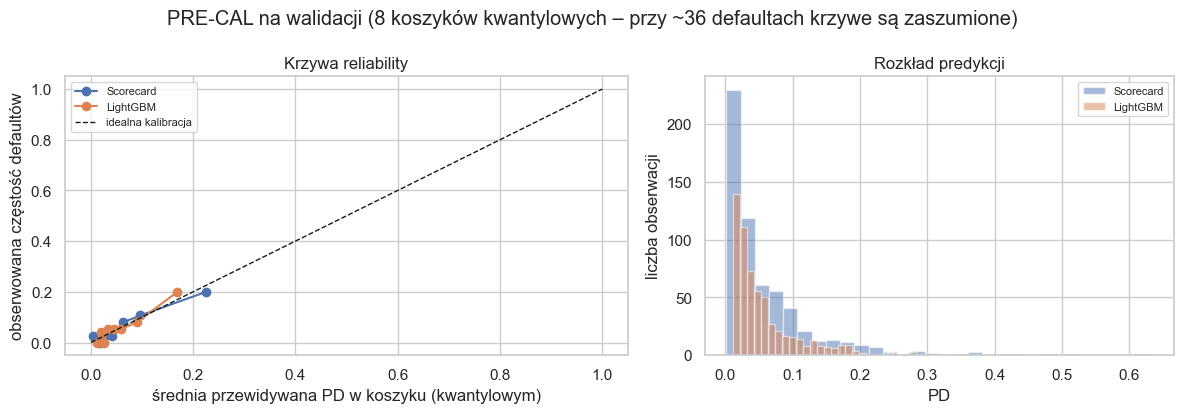

In [30]:
MODELS = ["Scorecard", "LightGBM"]
PIPES = {"Scorecard": pipe_lr, "LightGBM": pipe_bb}
P_VAL = {"Scorecard": p_val_lr, "LightGBM": p_val_bb}

from sklearn.calibration import calibration_curve


def plot_reliability(curves, title, fname=None, n_bins=8):
    """Rysuje krzywą reliability i histogram predykcji."""
    fig, (a1, a2) = plt.subplots(
        1, 2, figsize=(12, 4.2),
        gridspec_kw={"width_ratios": [1.2, 1]}
    )

    for lab, (y, p) in curves.items():
        obs, pred = calibration_curve(
            y, p, n_bins=n_bins, strategy="quantile"
        )
        a1.plot(pred, obs, "o-", label=lab)
        a2.hist(p, bins=30, alpha=.5, label=lab)

    a1.plot([0, 1], [0, 1], "k--", lw=1, label="idealna kalibracja")
    a1.set_xlabel("średnia przewidywana PD w koszyku (kwantylowym)")
    a1.set_ylabel("obserwowana częstość defaultów")
    a1.legend(fontsize=8)
    a1.set_title("Krzywa reliability")
    a2.set_xlabel("PD")
    a2.set_ylabel("liczba obserwacji")
    a2.legend(fontsize=8)
    a2.set_title("Rozkład predykcji")

    fig.suptitle(title)
    plt.tight_layout()
    if fname:
        plt.savefig(fname, dpi=150)
    plt.show()

pre_dict = {}
for m in MODELS:
    pre_dict[m] = all_metrics(yva, P_VAL[m])
pre = pd.DataFrame(pre_dict).T
display(pre[["AUC", "Brier", "LogLoss", "CITL", "Slope", "ECE", "mean_PD", "obs_rate"]])
print("CITL > 0 => model zaniża ryzyko, < 0 => zawyża; Slope < 1 => predykcje zbyt rozproszone (nadmierna pewność), > 1 => zbyt skupione.")

krzywe_pre = {}
for m in MODELS:
    krzywe_pre[m] = (yva, P_VAL[m])
plot_reliability(krzywe_pre, "PRE-CAL na walidacji (8 koszyków kwantylowych – przy ~36 defaultach krzywe są zaszumione)", "figures/reliability_precal.png")

### 5.2 Kalibracja statystyczna: Platt vs izotoniczna vs beta (CV wewnątrz validation) i wybór metody

In [31]:
class InterceptCalibrator:
    """Jednoparametrowa kalibracja interceptu: dopasowuje średnią przewidywaną PD do częstości defaultów
    w zbiorze kalibracyjnym. Nie zmienia rankingu ryzyka ani nachylenia predykcji."""
    name = "Intercept"

    def fit(self, p, y):
        self.delta_ = shift_to_mean(p, target=float(np.mean(y)))
        return self

    def predict(self, p):
        return apply_shift(p, self.delta_)


# słownik dostępnych kalibratorów (nazwa -> klasa)
CALS = {"brak": IdentityCalibrator,
        "Intercept": InterceptCalibrator,
        "Platt": PlattCalibrator,
        "Isotonic": IsotonicCalibrator,
        "Beta": BetaCalibrator}


def cv_in_val(p, y, cal_cls, n_rep=20, n_splits=5):
    """Ocenia kalibrator walidacją krzyżową wewnątrz zbioru validation (n_rep powtórzeń Stratified K-Fold).
    W każdym foldzie kalibrator uczy się na części danych i przewiduje na reszcie (predykcje out-of-fold).
    Zwraca: średnie metryk, odchylenia standardowe metryk oraz predykcje out-of-fold z 1. powtórzenia."""
    wyniki = []
    pierwsze_oof = None
    for powtorzenie in range(n_rep):
        oof = np.zeros(len(y))
        for a, b in StratifiedKFold(n_splits, shuffle=True, random_state=powtorzenie).split(p, y):
            kalibrator = cal_cls().fit(p[a], y[a])
            oof[b] = kalibrator.predict(p[b])
        wyniki.append(all_metrics(y, oof))
        if powtorzenie == 0:
            pierwsze_oof = oof
    tabela = pd.DataFrame(wyniki)
    return tabela.mean(), tabela.std(), pierwsze_oof


cal_rows = []
oof_first = {}
for m in MODELS:
    for name, cls in CALS.items():
        mu, sd, oof = cv_in_val(P_VAL[m], yva, cls)
        oof_first[(m, name)] = oof
        cal_rows.append({"model": m, "metoda": name, "Brier": mu["Brier"], "LogLoss": mu["LogLoss"],
                         "LogLoss_std": sd["LogLoss"], "CITL": mu["CITL"], "Slope": mu["Slope"],
                         "ECE": mu["ECE"], "AUC": mu["AUC"]})
cal_cmp = pd.DataFrame(cal_rows).set_index(["model", "metoda"])
display(cal_cmp)

# ============================================================
# WYBÓR KALIBRATORA
# ============================================================
# Log-loss jest główną metryką wyboru.
# Jeżeli kilka metod daje bardzo podobny wynik, preferujemy prostszą metodę.
CAL_COMPLEXITY = ["brak", "Intercept", "Platt", "Beta", "Isotonic"]   # od najprostszej do najbardziej złożonej
REL_TOL = 0.005   # tolerancja 0,5% względem najlepszego LogLoss

BEST_CAL = {}
for m in MODELS:
    t = cal_cmp.loc[m]

    # najniższy log-loss spośród wszystkich metod
    best_logloss = t["LogLoss"].min()

    # metody mieszczące się w tolerancji 0,5%
    eligible = t.index[t["LogLoss"] <= best_logloss * (1 + REL_TOL)].tolist()

    # bierzemy najprostszą z dopuszczonych metod
    selected = None
    for method in CAL_COMPLEXITY:
        if method in eligible:
            selected = method
            break
    BEST_CAL[m] = selected

# porównanie z wariantem bez kalibracji (różnice względem metody 'brak')
cal_cmp_view = cal_cmp.copy()
for m in MODELS:
    base_ll = cal_cmp.loc[(m, "brak"), "LogLoss"]
    base_bs = cal_cmp.loc[(m, "brak"), "Brier"]
    for method in CALS:
        cal_cmp_view.loc[(m, method), "ΔLogLoss"] = cal_cmp.loc[(m, method), "LogLoss"] - base_ll
        cal_cmp_view.loc[(m, method), "ΔBrier"] = cal_cmp.loc[(m, method), "Brier"] - base_bs

display(cal_cmp_view[["Brier", "LogLoss", "ΔBrier", "ΔLogLoss", "CITL", "Slope", "ECE", "AUC"]].round(5))

print("\nWYBRANE METODY:")
for m in MODELS:
    print(f"{m}: {BEST_CAL[m]}")

Brier  LogLoss  LogLoss_std    CITL  Slope    ECE    AUC
model     metoda                                                             
Scorecard brak      0.0499   0.1926       0.0000 -0.0212 0.9443 0.0137 0.7788
          Intercept 0.0499   0.1928       0.0002 -0.0031 0.9373 0.0137 0.7780
          Platt     0.0504   0.1953       0.0027  0.0002 0.9489 0.0147 0.7740
          Isotonic  0.0515   0.2111       0.0041 -0.0024 0.5826 0.0218 0.7461
          Beta      0.0509   0.1973       0.0027 -0.0027 0.8929 0.0175 0.7706
LightGBM  brak      0.0517   0.1994       0.0000  0.0613 1.1787 0.0169 0.7513
          Intercept 0.0517   0.1994       0.0001 -0.0017 1.1699 0.0140 0.7505
          Platt     0.0516   0.2008       0.0017  0.0002 0.9545 0.0128 0.7442
          Isotonic  0.0518   0.2166       0.0053 -0.0142 0.5385 0.0208 0.7031
          Beta      0.0511   0.2002       0.0018 -0.0019 0.9265 0.0153 0.7386

Brier  LogLoss  ΔBrier  ΔLogLoss    CITL  Slope    ECE    AUC
model     metoda                                                                  
Scorecard brak      0.0499   0.1926  0.0000    0.0000 -0.0212 0.9443 0.0137 0.7788
          Intercept 0.0499   0.1928  0.0000    0.0003 -0.0031 0.9373 0.0137 0.7780
          Platt     0.0504   0.1953  0.0006    0.0027  0.0002 0.9489 0.0147 0.7740
          Isotonic  0.0515   0.2111  0.0016    0.0185 -0.0024 0.5826 0.0218 0.7461
          Beta      0.0509   0.1973  0.0010    0.0047 -0.0027 0.8929 0.0175 0.7706
LightGBM  brak      0.0517   0.1994  0.0000    0.0000  0.0613 1.1787 0.0169 0.7513
          Intercept 0.0517   0.1994 -0.0001    0.0001 -0.0017 1.1699 0.0140 0.7505
          Platt     0.0516   0.2009 -0.0001    0.0014  0.0001 0.9545 0.0128 0.7442
          Isotonic  0.0518   0.2166  0.0001    0.0173 -0.0142 0.5385 0.0208 0.7031
          Beta      0.0511   0.2002 -0.0006    0.0008 -0.0019 0.9265 0.0153 0.7386


WYBRANE METODY:
Scorecard: brak
LightGBM: brak


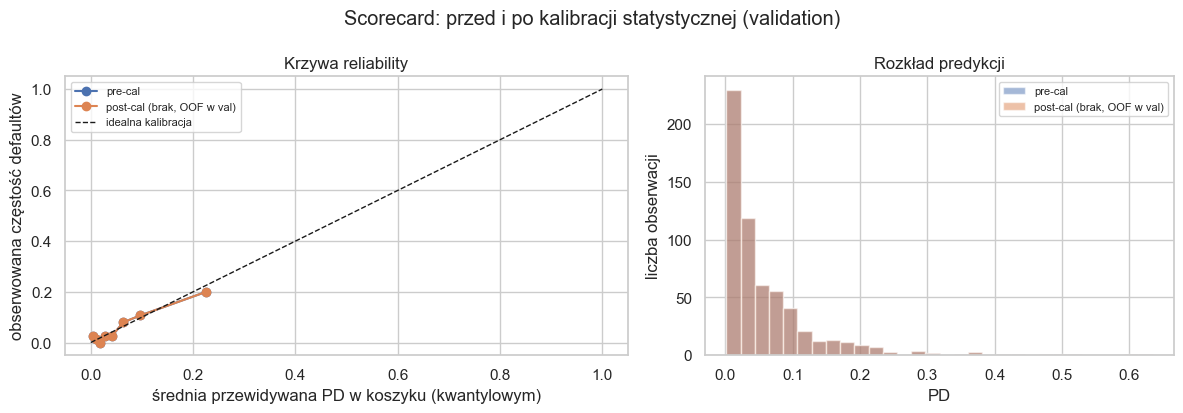

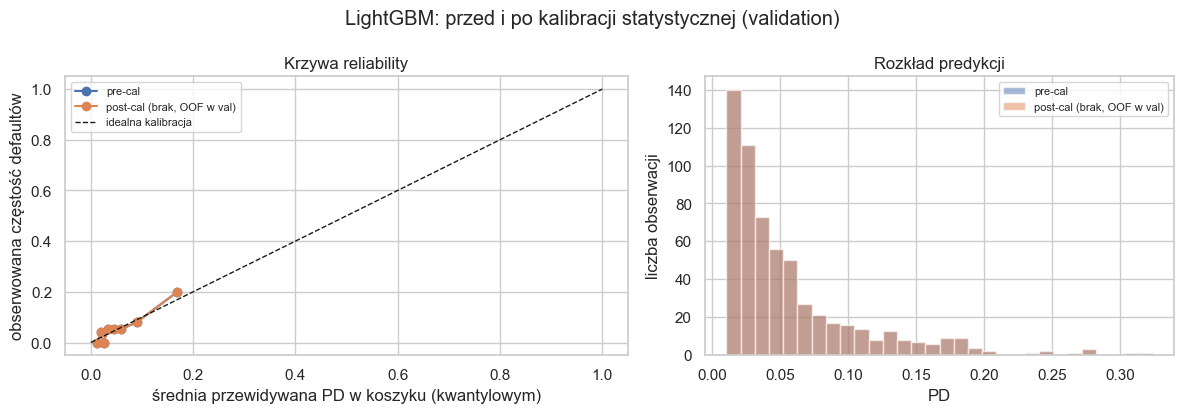

In [32]:
# post-cal (uczciwie: predykcje out-of-fold wewnątrz validation, 1. powtórzenie) – krzywe i metryki
for m in MODELS:
    krzywe = {"pre-cal": (yva, P_VAL[m]),
              f"post-cal ({BEST_CAL[m]}, OOF w val)": (yva, oof_first[(m, BEST_CAL[m])])}
    plot_reliability(krzywe, f"{m}: przed i po kalibracji statystycznej (validation)", f"figures/reliability_postcal_{m}.png")

### 5.3 Dostosowanie do PD = 4% (tendencja centralna)

Kalibracja statystyczna (5.2) dopasowuje PD do częstości defaultów w danych. Dostosowanie do 4% to zewnętrzne założenie biznesowe o docelowym portfelu: przesuwamy intercept w skali logitowej o stałą δ tak, by średnia PD w populacji referencyjnej (= validation, bez testu) wynosiła 4%. Przesunięcie jest monotoniczne, więc nie zmienia rankingu (AUC bez zmian).

In [33]:
TARGET_PD = 0.04

# kalibratory dopasowane na validation (wybrana metoda dla każdego modelu)
cal_final = {}
p_val_cal = {}
delta = {}
p_val_4 = {}
for m in MODELS:
    cal_final[m] = CALS[BEST_CAL[m]]().fit(P_VAL[m], yva)
    p_val_cal[m] = cal_final[m].predict(P_VAL[m])
    # korekta CITL wyznaczona na populacji referencyjnej (validation)
    delta[m] = shift_to_mean(p_val_cal[m], TARGET_PD)
    p_val_4[m] = apply_shift(p_val_cal[m], delta[m])

# tabela podsumowująca (po jednej kolumnie na model)
sr_pre = []
sr_cal = []
delty = []
mnozniki = []
sr_4 = []
for m in MODELS:
    sr_pre.append(P_VAL[m].mean())
    sr_cal.append(p_val_cal[m].mean())
    delty.append(delta[m])
    mnozniki.append(np.exp(delta[m]))
    sr_4.append(p_val_4[m].mean())

ref = pd.DataFrame({"default rate train": ytr.mean(),
                    "default rate validation (referencja)": yva.mean(),
                    "założone PD": TARGET_PD,
                    "śr. PD pre-cal (val)": sr_pre,
                    "śr. PD po kalibracji stat. (val)": sr_cal,
                    "δ (logit)": delty,
                    "mnożnik szans exp(δ)": mnozniki,
                    "śr. PD po korekcie 4% (val)": sr_4}, index=MODELS)
display(ref.T)

if yva.mean() > TARGET_PD:
    porownanie = "wyższa"
else:
    porownanie = "niższa"
if delta[MODELS[0]] < 0:
    kierunek_korekty = "obniża"
else:
    kierunek_korekty = "podnosi"
print(f"Częstość defaultów w danych ({yva.mean():.1%}) jest {porownanie} niż 4% – korekta {kierunek_korekty} PD względem próby.")

,Scorecard,LightGBM
default rate train,0.0589,0.0589
default rate validation (referencja),0.0600,0.0600
założone PD,0.0400,0.0400
śr. PD pre-cal (val),0.0611,0.0568
śr. PD po kalibracji stat. (val),0.0611,0.0568
δ (logit),-0.4936,-0.3848
mnożnik szans exp(δ),0.6104,0.6806
śr. PD po korekcie 4% (val),0.0400,0.0400


Częstość defaultów w danych (6.0%) jest wyższa niż 4% – korekta obniża PD względem próby.


#### Ocena na niezależnym zbiorze testowym

TEST: n=600, defaulty=36 (6.00%)


AUC  PR_AUC     KS  LogLoss  Brier    CITL  Slope    ECE  mean_PD  obs_rate
model     etap                                                                                                
Scorecard surowy                0.7813  0.2428 0.4858   0.1946 0.0509 -0.0140 0.9268 0.0095   0.0607    0.0600
          po kalibracji stat.   0.7813  0.2428 0.4858   0.1946 0.0509 -0.0140 0.9268 0.0095   0.0607    0.0600
          po dostosowaniu do 4% 0.7813  0.2428 0.4858   0.1998 0.0518  0.4796 0.9271 0.0220   0.0395    0.0600
LightGBM  surowy                0.8044  0.2472 0.5195   0.1928 0.0517 -0.0136 1.3200 0.0133   0.0607    0.0600
          po kalibracji stat.   0.8044  0.2472 0.5195   0.1928 0.0517 -0.0136 1.3200 0.0133   0.0607    0.0600
          po dostosowaniu do 4% 0.8044  0.2472 0.5195   0.1961 0.0527  0.3712 1.3201 0.0246   0.0429    0.0600

Metryki przy reważeniu testu do prevalencji 4% (obs_rate = 4% z konstrukcji):


LogLoss  Brier    CITL  Slope  mean_PD  obs_rate
model     etap                                                                   
Scorecard po kalibracji stat.     0.1495 0.0364 -0.4405 0.9322   0.0587    0.0400
          po dostosowaniu do 4%   0.1456 0.0356  0.0530 0.9324   0.0382    0.0400
LightGBM  po kalibracji stat.     0.1485 0.0365 -0.4345 1.3252   0.0594    0.0400
          po dostosowaniu do 4%   0.1446 0.0361 -0.0497 1.3192   0.0419    0.0400

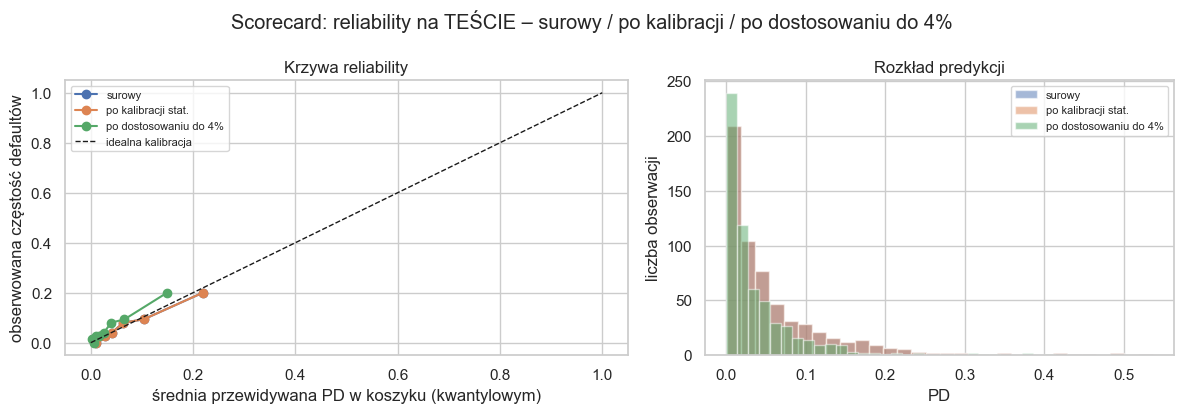

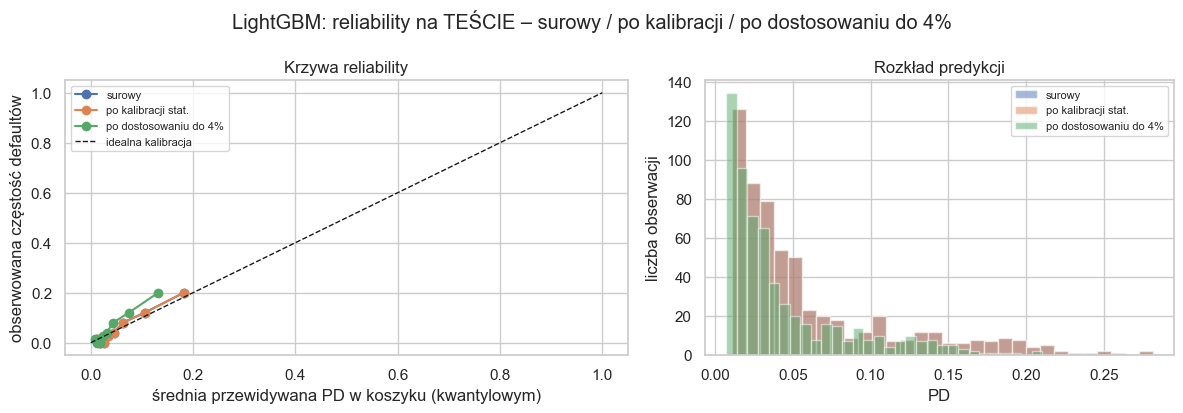

,mean,min,10%,50%,90%,99%,max
Scorecard | surowy,0.0607,0.0010,0.0060,0.0334,0.1520,0.4165,0.5359
Scorecard | po kalibracji stat.,0.0607,0.0010,0.0060,0.0334,0.1520,0.4165,0.5359
Scorecard | po dostosowaniu do 4%,0.0395,0.0006,0.0036,0.0207,0.0986,0.3035,0.4134
LightGBM | surowy,0.0607,0.0106,0.0141,0.0394,0.1494,0.2308,0.2815
LightGBM | po kalibracji stat.,0.0607,0.0106,0.0141,0.0394,0.1494,0.2308,0.2815
LightGBM | po dostosowaniu do 4%,0.0429,0.0072,0.0096,0.0272,0.1068,0.1696,0.2105


In [34]:
Xte = df.iloc[idx_test]
yte = y_all[idx_test]

# predykcje na teście: surowe, po kalibracji statystycznej, po dostosowaniu do 4%
p_te_raw = {}
p_te_cal = {}
p_te_4 = {}
for m in MODELS:
    p_te_raw[m] = PIPES[m].predict_proba(Xte)[:, 1]
    p_te_cal[m] = cal_final[m].predict(p_te_raw[m])
    p_te_4[m] = apply_shift(p_te_cal[m], delta[m])
print(f"TEST: n={len(yte)}, defaulty={yte.sum()} ({yte.mean():.2%})")


def stages(m):
    """Zwraca listę trzech etapów predykcji na teście dla modelu m: (nazwa etapu, wektor PD)."""
    return [("surowy", p_te_raw[m]), ("po kalibracji stat.", p_te_cal[m]), ("po dostosowaniu do 4%", p_te_4[m])]


# metryki na teście dla każdego modelu i etapu
wiersze_test = []
for m in MODELS:
    for s, p in stages(m):
        wiersz = {"model": m, "etap": s}
        wiersz.update(all_metrics(yte, p))
        wiersze_test.append(wiersz)
test_tab = pd.DataFrame(wiersze_test).set_index(["model", "etap"])
display(test_tab[["AUC", "PR_AUC", "KS", "LogLoss", "Brier", "CITL", "Slope", "ECE", "mean_PD", "obs_rate"]])

# ocena przy założeniu przesunięcia prevalencji do 4%
# (waga: defaulty 0.04/π_test, dobrzy 0.96/(1−π_test)); zakłada stałe rozkłady cech w klasach
w_te = np.where(yte == 1, TARGET_PD / yte.mean(), (1 - TARGET_PD) / (1 - yte.mean()))
metryki_wazone = ["Brier", "LogLoss", "CITL", "Slope", "mean_PD", "obs_rate"]
wiersze_wazone = []
for m in MODELS:
    for s, p in stages(m)[1:]:
        wiersz = {"model": m, "etap": s}
        for k, v in all_metrics(yte, p, w_te).items():
            if k in metryki_wazone:
                wiersz[k] = v
        wiersze_wazone.append(wiersz)
wtab = pd.DataFrame(wiersze_wazone).set_index(["model", "etap"])
print("Metryki przy reważeniu testu do prevalencji 4% (obs_rate = 4% z konstrukcji):")
display(wtab)

# krzywe reliability na teście
for m in MODELS:
    krzywe = {}
    for s, p in stages(m):
        krzywe[s] = (yte, p)
    plot_reliability(krzywe, f"{m}: reliability na TEŚCIE – surowy / po kalibracji / po dostosowaniu do 4%", f"figures/reliability_test_{m}.png")

# rozkład PD na teście
dist_dict = {}
for m in MODELS:
    for s, p in stages(m):
        dist_dict[f"{m} | {s}"] = pd.Series(p).describe(percentiles=[.1, .5, .9, .99])
dist = pd.DataFrame(dist_dict).T[["mean", "min", "10%", "50%", "90%", "99%", "max"]]
display(dist)

## 6. Progi decyzji, ratingi i analiza kontrfaktyczna (3.6)

### 6.1 Funkcja kosztu/korzyści i próg operacyjny
Założenia do zmiany przez zespół (ilustracyjne): zysk z obsłużenia dobrego klienta = MARGIN (% ekspozycji), strata na defaulcie = LGD (% ekspozycji). Odrzucamy klienta, gdy PD ≥ próg. Pozytyw = odrzucenie: TP – odrzucony default; FP – odrzucony dobry (utracona marża); FN – przyjęty default (strata LGD); TN – przyjęty dobry. Zysk = MARGIN·TN − LGD·FN. Teoretyczny próg opłacalności (przy poprawnie skalibrowanej PD): MARGIN/(MARGIN+LGD).

Próg wybieramy na validation (zysk empiryczny na PD po kalibracji statystycznej, czyli w skali częstości z próby), a jego odpowiednik w skali PD po korekcie 4% wyznaczamy odwrotnym przesunięciem.

,próg* (skala próby),próg* (skala PD 4%),% odrzuceń na val przy progu*,zysk/klienta na val przy progu*,zysk/klienta: przyjmij wszystkich,próg teoretyczny (skala 4%),próg teoretyczny przeliczony na skalę próby
Scorecard,0.1585,0.1031,8.8333,0.0369,0.0294,0.1176,0.1793
LightGBM,0.1809,0.1307,3.5000,0.0367,0.0294,0.1176,0.1638


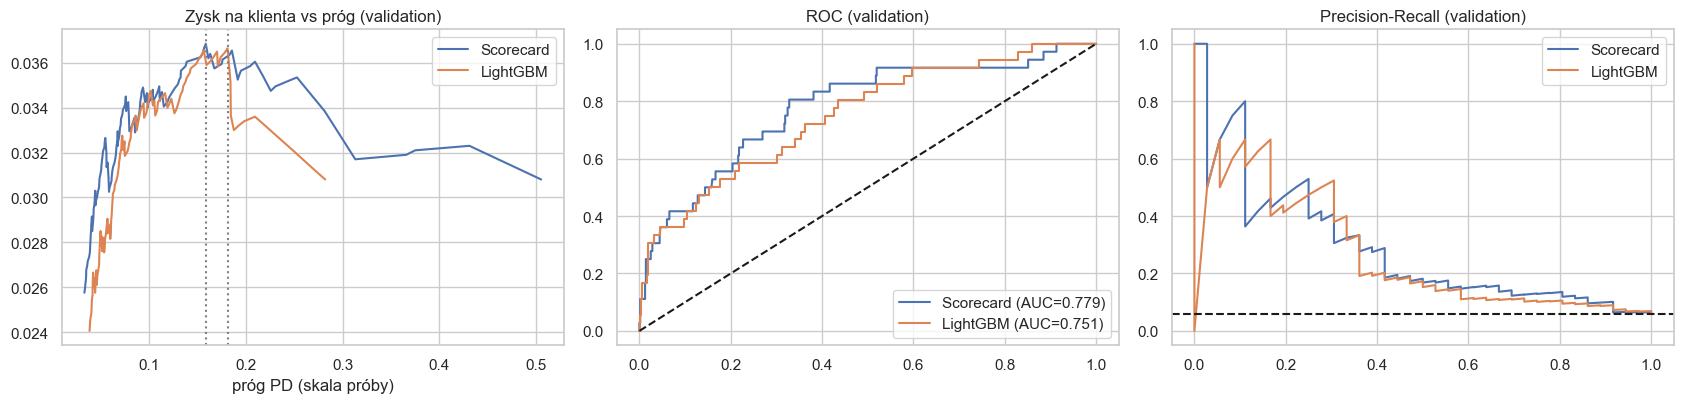

In [35]:
MARGIN = 0.06
LGD = 0.45
t_theory = MARGIN / (MARGIN + LGD)

t_star = {}
krzywe_zysku = {}
for m in MODELS:
    # siatka progów: kwantyle PD po kalibracji (od mediany do 99,5%)
    grid_t = np.unique(np.quantile(p_val_cal[m], np.linspace(0.5, 0.995, 150)))
    lista_decyzji = []
    for t in grid_t:
        lista_decyzji.append(decision_table(yva, p_val_cal[m], t, MARGIN, LGD))
    cu = pd.DataFrame(lista_decyzji)
    krzywe_zysku[m] = cu
    # próg optymalny = ten, który daje największy zysk na klienta
    t_star[m] = float(cu.loc[cu.zysk_na_klienta.idxmax(), "prog"])

# zysk, gdybyśmy przyjmowali wszystkich
base_profit = MARGIN * (1 - yva.mean()) - LGD * yva.mean()

prog_proby = {}
prog_4 = {}
odrzucenia = {}
zysk_max = {}
prog_teor_proby = {}
for m in MODELS:
    prog_proby[m] = t_star[m]
    prog_4[m] = float(apply_shift(t_star[m], delta[m]))
    odrzucenia[m] = 100 * (p_val_cal[m] >= t_star[m]).mean()
    zysk_max[m] = krzywe_zysku[m].zysk_na_klienta.max()
    prog_teor_proby[m] = float(apply_shift(t_theory, -delta[m]))

thr_tab = pd.DataFrame({"próg* (skala próby)": pd.Series(prog_proby),
                        "próg* (skala PD 4%)": pd.Series(prog_4),
                        "% odrzuceń na val przy progu*": pd.Series(odrzucenia),
                        "zysk/klienta na val przy progu*": pd.Series(zysk_max)})
thr_tab["zysk/klienta: przyjmij wszystkich"] = base_profit
thr_tab["próg teoretyczny (skala 4%)"] = t_theory
thr_tab["próg teoretyczny przeliczony na skalę próby"] = pd.Series(prog_teor_proby)
display(thr_tab)

# wykresy: zysk vs próg, ROC, Precision-Recall
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for m in MODELS:
    ax[0].plot(krzywe_zysku[m].prog, krzywe_zysku[m].zysk_na_klienta, label=m)
    ax[0].axvline(t_star[m], ls=":", color="grey")
    fpr, tpr, _ = roc_curve(yva, p_val_cal[m])
    ax[1].plot(fpr, tpr, label=f"{m} (AUC={roc_auc_score(yva, p_val_cal[m]):.3f})")
    pr, rc, _ = precision_recall_curve(yva, p_val_cal[m])
    ax[2].plot(rc, pr, label=m)
ax[0].set_title("Zysk na klienta vs próg (validation)")
ax[0].set_xlabel("próg PD (skala próby)")
ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_title("ROC (validation)")
ax[1].legend()
ax[2].set_title("Precision-Recall (validation)")
ax[2].axhline(yva.mean(), color="k", ls="--")
ax[2].legend()
plt.tight_layout()
plt.savefig("figures/thresholds.png", dpi=150)
plt.show()

In [36]:
# tabele decyzyjne na TEŚCIE: (a) próg* wybrany na validation,
# (b) wrażliwość na próg przez poziom odrzuceń ustalony na validation
rows = []
for m in MODELS:
    wiersz = {"model": m, "wariant": "próg* (val)"}
    wiersz.update(decision_table(yte, p_te_cal[m], t_star[m], MARGIN, LGD))
    rows.append(wiersz)

    for r in [5, 10, 15, 20, 30]:
        prog_r = float(np.quantile(p_val_cal[m], 1 - r / 100))
        wiersz = {"model": m, "wariant": f"odrzuć ~{r}% (próg z val)"}
        wiersz.update(decision_table(yte, p_te_cal[m], prog_r, MARGIN, LGD))
        rows.append(wiersz)

    # próg 1.01 oznacza, że nikt nie jest odrzucany
    wiersz = {"model": m, "wariant": "przyjmij wszystkich"}
    wiersz.update(decision_table(yte, p_te_cal[m], 1.01, MARGIN, LGD))
    rows.append(wiersz)

dec_tab = pd.DataFrame(rows).set_index(["model", "wariant"])
display(dec_tab)

# porównanie decyzji obu modeli przy własnych progach*
rej = {}
for m in MODELS:
    rej[m] = p_te_cal[m] >= t_star[m]
print(f"Zgodność decyzji: {np.mean(rej['Scorecard'] == rej['LightGBM']):.1%} | kappa Cohena: {cohen_kappa_score(rej['Scorecard'], rej['LightGBM']):.2f}")
display(pd.crosstab(pd.Series(rej["Scorecard"], name="Scorecard odrzuca"), pd.Series(rej["LightGBM"], name="LightGBM odrzuca")))

prog  odrzucenia_proc  TP   FP  FN   TN  bad_rate_przyjetych  recall_defaultow  zysk_na_klienta
model     wariant                                                                                                                   
Scorecard próg* (val)              0.1585           9.5000  13   44  23  520               0.0424            0.3611           0.0348
          odrzuć ~5% (próg z val)  0.1998           5.3333  11   21  25  543               0.0440            0.3056           0.0355
          odrzuć ~10% (próg z val) 0.1419          11.3333  14   54  22  510               0.0414            0.3889           0.0345
          odrzuć ~15% (próg z val) 0.1102          17.1667  18   85  18  479               0.0362            0.5000           0.0344
          odrzuć ~20% (próg z val) 0.0910          22.0000  21  111  15  453               0.0321            0.5833           0.0340
          odrzuć ~30% (próg z val) 0.0673          30.0000  27  153   9  411               0.0214            0.7500           0.0343
          przyjmij wszystkich      1.0100           0.0000   0    0  36  564               0.0600            0.0000           0.0294
LightGBM  próg* (val)              0.1809           5.8333   9   26  27  538               0.0478            0.2500           0.0336
          odrzuć ~5% (próg z val)  0.1707           7.6667  10   36  26  528               0.0469            0.2778           0.0333
          odrzuć ~10% (próg z val) 0.1317          12.8333  16   61  20  503               0.0382            0.4444           0.0353
          odrzuć ~15% (próg z val) 0.1025          19.8333  21   98  15  466               0.0312            0.5833           0.0353
          odrzuć ~20% (próg z val) 0.0856          23.1667  24  115  12  449               0.0260            0.6667           0.0359
          odrzuć ~30% (próg z val) 0.0611          31.3333  27  161   9  403               0.0218            0.7500           0.0335
          przyjmij wszystkich      1.0100           0.0000   0    0  36  564               0.0600            0.0000           0.0294

Zgodność decyzji: 94.0% | kappa Cohena: 0.58


LightGBM odrzuca,False,True
Scorecard odrzuca,,
False,536,7
True,29,28


### 6.2 Mapowanie PD → klasy ratingowe
Skala nadrzędna na PD po korekcie 4% (progi: 0,5%, 1%, 2%, 4%, 8%, 15% → AAA, AA, A, BBB, BB, B, CCC); po scaleniu klasa dostaje etykietę klasy skali nadrzędnej, w której leży jej średnia PD (dzięki temu etykiety są porównywalne między modelami). Granice są dopasowywane na validation: sąsiednie klasy są łączone, jeśli obserwowana częstość defaultów nie rośnie z klasą albo klasa ma < 15 obserwacji. Dzięki temu zachowana jest monotoniczność (średnia PD rośnie z klasą z konstrukcji, a obserwowana częstość po scaleniu na zbiorze referencyjnym).

Scorecard: granice PD(4%) = [0.02, 0.04, 0.08, 0.15] -> klasy ['AA', 'BBB', 'BB', 'B', 'CCC']
LightGBM: granice PD(4%) = [0.01, 0.02, 0.08] -> klasy ['AA', 'A', 'BBB', 'B']

=== Scorecard: VALIDATION (monotoniczność średniej PD, obs. częstości): (True, True)


,n,defaulty,srednia_PD,obs_default_rate,udzial_%,CI95_lo,CI95_hi
klasa,,,,,,,
AA,297,5,0.0092,0.0168,49.5000,0.0072,0.0388
BBB,112,6,0.0287,0.0536,18.6667,0.0248,0.1120
BB,117,10,0.0554,0.0855,19.5000,0.0471,0.1502
B,50,5,0.1093,0.1000,8.3333,0.0435,0.2136
CCC,24,10,0.2546,0.4167,4.0000,0.2447,0.6117


=== Scorecard: TEST (monotoniczność średniej PD, obs. częstości): (True, True)


,n,defaulty,srednia_PD,obs_default_rate,udzial_%,CI95_lo,CI95_hi
klasa,,,,,,,
AA,296,5,0.0088,0.0169,49.3333,0.0072,0.0389
BBB,119,4,0.0287,0.0336,19.8333,0.0131,0.0832
BB,100,11,0.0569,0.1100,16.6667,0.0625,0.1863
B,66,9,0.1099,0.1364,11.0000,0.0734,0.2393
CCC,19,7,0.2505,0.3684,3.1667,0.1915,0.5896


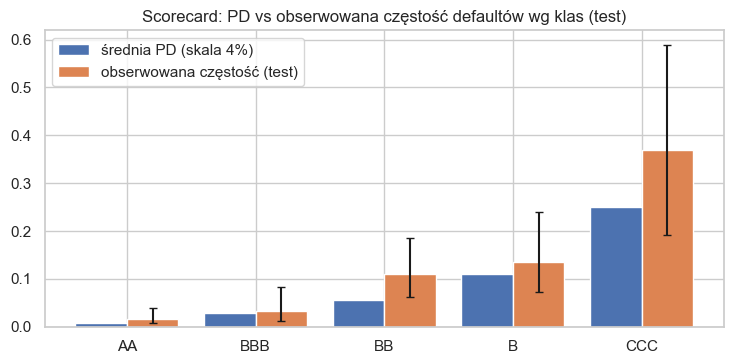


=== LightGBM: VALIDATION (monotoniczność średniej PD, obs. częstości): (True, True)


,n,defaulty,srednia_PD,obs_default_rate,udzial_%,CI95_lo,CI95_hi
klasa,,,,,,,
AA,63,0,0.0086,0.0000,10.5000,-0.0000,0.0575
A,158,3,0.0147,0.0190,26.3333,0.0065,0.0543
BBB,302,18,0.0391,0.0596,50.3333,0.0380,0.0922
B,77,15,0.1213,0.1948,12.8333,0.1218,0.2969


=== LightGBM: TEST (monotoniczność średniej PD, obs. częstości): (True, False)


,n,defaulty,srednia_PD,obs_default_rate,udzial_%,CI95_lo,CI95_hi
klasa,,,,,,,
AA,68,1,0.0087,0.0147,11.3333,0.0026,0.0787
A,151,0,0.0146,0.0000,25.1667,0.0000,0.0248
BBB,284,15,0.0390,0.0528,47.3333,0.0323,0.0853
B,97,20,0.1222,0.2062,16.1667,0.1376,0.2971


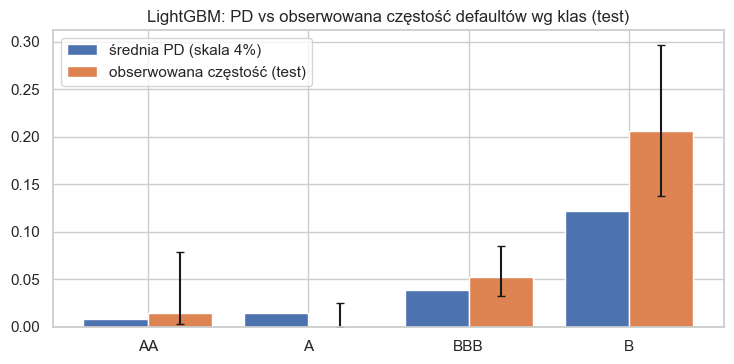

In [37]:
from scorecard import RATING_LABELS

BOUNDS0 = [0.005, 0.01, 0.02, 0.04, 0.08, 0.15]

# granice i etykiety klas dla każdego modelu (dopasowane na validation)
rating_def = {}
for m in MODELS:
    b = monotone_bounds(p_val_4[m], yva, BOUNDS0, min_n=15)
    etykiety = labels_from_master(p_val_4[m], b, BOUNDS0)
    rating_def[m] = (b, etykiety)
    print(f"{m}: granice PD(4%) = {[round(x, 4) for x in b]} -> klasy {etykiety}")


def monotonicznosc(t):
    """Sprawdza dla tabeli ratingowej t, czy średnia PD i obserwowana częstość defaultów rosną z klasą.
    Zwraca parę (czy rośnie średnia PD, czy rośnie obserwowana częstość)."""
    roznice_pd = np.diff(t["srednia_PD"].dropna().values)
    roznice_obs = np.diff(t["obs_default_rate"].dropna().values)
    return (bool(np.all(roznice_pd > 0)), bool(np.all(roznice_obs > 0)))


for m in MODELS:
    granice, etykiety = rating_def[m]
    tv = rating_table(p_val_4[m], yva, granice, etykiety)
    tt = rating_table(p_te_4[m], yte, granice, etykiety)

    print(f"\n=== {m}: VALIDATION (monotoniczność średniej PD, obs. częstości): {monotonicznosc(tv)}")
    display(tv)
    print(f"=== {m}: TEST (monotoniczność średniej PD, obs. częstości): {monotonicznosc(tt)}")
    display(tt)

    # wykres: średnia PD vs obserwowana częstość w klasach (test) z przedziałami ufności
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    x = np.arange(len(tt))
    blad_dol = tt["obs_default_rate"] - tt["CI95_lo"]
    blad_gora = tt["CI95_hi"] - tt["obs_default_rate"]
    ax.bar(x - .2, tt["srednia_PD"], .4, label="średnia PD (skala 4%)")
    ax.bar(x + .2, tt["obs_default_rate"], .4, label="obserwowana częstość (test)", yerr=[blad_dol, blad_gora], capsize=3)
    ax.set_xticks(x)
    ax.set_xticklabels(tt.index)
    ax.set_title(f"{m}: PD vs obserwowana częstość defaultów wg klas (test)")
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"figures/ratings_{m}.png", dpi=150)
    plt.show()

In [38]:
# macierz migracji ratingów między modelami (test)
cl = {}
for m in MODELS:
    granice, etykiety = rating_def[m]
    cl[m] = assign_rating(p_te_4[m], granice, etykiety)


def cat(a):
    """Zamienia listę etykiet ratingowych na zmienną kategoryczną z uporządkowanymi klasami (AAA ... CCC)."""
    return pd.Categorical(a, categories=RATING_LABELS, ordered=True)


display(pd.crosstab(cat(cl["Scorecard"]), cat(cl["LightGBM"]), rownames=["Scorecard"], colnames=["LightGBM"], dropna=False))

# różnica w liczbie klas między modelami dla każdego klienta
pos = {}
for i in range(len(RATING_LABELS)):
    pos[RATING_LABELS[i]] = i
poz_sc = np.array([pos[a] for a in cl["Scorecard"]])
poz_lgbm = np.array([pos[b] for b in cl["LightGBM"]])
dd = np.abs(poz_sc - poz_lgbm)
print(f"Ta sama klasa: {np.mean(dd == 0):.1%} | różnica ≤1 klasy: {np.mean(dd <= 1):.1%} (uwaga: modele mogą mieć różną liczbę klas po scaleniu)")

LightGBM,AAA,AA,A,BBB,BB,B,CCC
Scorecard,,,,,,,
AAA,0,0,0,0,0,0,0
AA,0,68,137,91,0,0,0
A,0,0,0,0,0,0,0
BBB,0,0,13,103,0,3,0
BB,0,0,1,72,0,27,0
B,0,0,0,16,0,50,0
CCC,0,0,0,2,0,17,0


Ta sama klasa: 36.8% | różnica ≤1 klasy: 81.2% (uwaga: modele mogą mieć różną liczbę klas po scaleniu)


### 6.3 Audyt podgrup (test)
Szybki audyt różnic jakości i PD w podgrupach: wielkość firmy (kwartyle `Aktywa` z train) oraz forma własności. Liczebności defaultów w podgrupach są bardzo małe (kilka–kilkanaście), więc AUC jest raportowane tylko przy ≥5 defaultach i ≥5 dobrych, a wnioski mają charakter orientacyjny.

In [39]:
# podział na kwartyle wielkości firmy (granice z train)
kwartyle = Xtr["Aktywa"].quantile([.25, .5, .75]).values
akt_edges = np.r_[-np.inf, kwartyle, np.inf]
g_akt = pd.cut(Xte["Aktywa"], akt_edges, labels=["Q1 małe", "Q2", "Q3", "Q4 duże"])

# forma własności: rzadkie formy (< 100 obserwacji w train) łączymy w grupę "inne"
frequent = Xtr["forma_wl"].value_counts()
frequent = frequent[frequent >= 100].index
g_forma = Xte["forma_wl"].where(Xte["forma_wl"].isin(frequent), "inne")

grupy = {"wielkość (Aktywa)": g_akt, "forma własności": g_forma}
aud = []
for gname, g in grupy.items():
    for lvl in g.dropna().unique():
        mask = (g == lvl).values
        n = int(mask.sum())
        d = int(yte[mask].sum())
        for m in MODELS:
            # AUC liczymy tylko, gdy jest dość defaultów i dobrych klientów
            if d >= 5 and n - d >= 5:
                auc_grupy = roc_auc_score(yte[mask], p_te_4[m][mask])
            else:
                auc_grupy = np.nan
            aud.append({"grupa": gname, "poziom": str(lvl), "model": m, "n": n, "defaulty": d, "AUC": auc_grupy,
                        "Brier_po_kal_stat": np.mean((p_te_cal[m][mask] - yte[mask]) ** 2),
                        "sr_PD_4proc": p_te_4[m][mask].mean(), "obs_rate": yte[mask].mean()})
display(pd.DataFrame(aud).sort_values(["grupa", "poziom", "model"]).set_index(["grupa", "poziom", "model"]))

n  defaulty    AUC  Brier_po_kal_stat  sr_PD_4proc  obs_rate
grupa             poziom  model                                                                    
forma własności   214     LightGBM   402        21 0.7702             0.0463       0.0448    0.0522
                          Scorecard  402        21 0.7520             0.0453       0.0374    0.0522
                  215     LightGBM    62         5 0.9298             0.0624       0.0403    0.0806
                          Scorecard   62         5 0.8947             0.0614       0.0412    0.0806
                  216     LightGBM    33         2    NaN             0.0465       0.0336    0.0606
                          Scorecard   33         2    NaN             0.0412       0.0435    0.0606
                  inne    LightGBM   103         8 0.8118             0.0682       0.0399    0.0777
                          Scorecard  103         8 0.7750             0.0696       0.0456    0.0777
wielkość (Aktywa) Q1 małe LightGBM   163        15 0.6401             0.0826       0.0662    0.0920
                          Scorecard  163        15 0.6286             0.0839       0.0560    0.0920
                  Q2      LightGBM   157         9 0.8679             0.0468       0.0456    0.0573
                          Scorecard  157         9 0.8198             0.0468       0.0465    0.0573
                  Q3      LightGBM   137         7 0.9022             0.0418       0.0330    0.0511
                          Scorecard  137         7 0.8352             0.0419       0.0322    0.0511
                  Q4 duże LightGBM   143         5 0.7594             0.0314       0.0228    0.0350
                          Scorecard  143         5 0.7551             0.0265       0.0202    0.0350

### 6.4 Analiza kontrfaktyczna

Cel: dla jednej obserwacji (walidacja, nie-default, scorecard-rating BB) znaleźć najmniejszą realistyczną zmianę wskaźników, która poprawi rating o jedną klasę (BB → BBB), tj. obniży PD (po korekcie 4%) poniżej granicy klas.

Założenia realistyczności:
* zmieniamy tylko wskaźniki użyte w scorecardzie (bez wielkości firmy i zmiennych spoza opisu), w kierunku zmniejszającym ryzyko, w zakresie p5–p95 rozkładu train (bez ekstrapolacji), do 1 lub 2 wskaźników jednocześnie,
* koszt zmiany = przesunięcie w percentylach rozkładu train (porównywalne między wskaźnikami), limit 50 pkt percentylowych na wskaźnik,
* zależności między cechami: gdy zmieniamy wskaźnik, skorelowane z nim wskaźniki (|ρ Spearmana| ≥ 0,7) przesuwają się razem wg regresji liniowej z train (z obcięciem do zakresu p1–p99),
* weryfikujemy wynik także w modelu black-box.

In [40]:
labels_lr = rating_def["Scorecard"][1]
bounds_lr = rating_def["Scorecard"][0]
assert len(labels_lr) >= 2, "Za mało klas ratingowych po scaleniu – zmień BOUNDS0/min_n"

# ci = pozycja klasy, którą chcemy poprawić (najchętniej BB)
if "BB" in labels_lr and labels_lr.index("BB") >= 1:
    ci = labels_lr.index("BB")
else:
    ci = min(len(labels_lr) - 2, max(1, len(labels_lr) // 2 + 1))

# kandydaci: obserwacje z walidacji z tej klasy, które nie są defaultami
cls_val = assign_rating(p_val_4["Scorecard"], bounds_lr, labels_lr)
cand = np.where((cls_val == labels_lr[ci]) & (yva == 0))[0]
if len(cand) == 0:
    cand = np.where(cls_val == labels_lr[ci])[0]

# bierzemy obserwację o PD najbliższej medianie PD kandydatów
pd_kand = p_val_4["Scorecard"][cand]
i_cf = int(cand[np.argmin(np.abs(pd_kand - np.median(pd_kand)))])

boundary = bounds_lr[ci - 1]     # granica, którą musimy przekroczyć (w dół)
target_pd = boundary * 0.98


def pd4(m, rows):
    """PD po kalibracji statystycznej i korekcie do 4% dla modelu m (dla podanych surowych wierszy cech)."""
    p_surowe = PIPES[m].predict_proba(rows)[:, 1]
    p_kal = cal_final[m].predict(p_surowe)
    return apply_shift(p_kal, delta[m])


base = Xva.iloc[[i_cf]]
print(f"Obserwacja (val, pozycja {i_cf}): y={yva[i_cf]} | rating scorecard: {labels_lr[ci]} -> cel: {labels_lr[ci - 1]} | PD(4%) scorecard={pd4('Scorecard', base)[0]:.4f}, LightGBM={pd4('LightGBM', base)[0]:.4f} | cel PD < {target_pd:.4f}")

Obserwacja (val, pozycja 563): y=0 | rating scorecard: BB -> cel: BBB | PD(4%) scorecard=0.0547, LightGBM=0.0743 | cel PD < 0.0392


In [41]:
# dźwignie (wskaźniki, które wolno zmieniać) i zależności między wskaźnikami
iv_t = prep_lr.iv_table_

LEVERS = []
for c in feats_lr:
    f = raw_name(c)
    if f in RATIO_COLS and f not in SUSPICIOUS and not np.isnan(base[f].iloc[0]):
        LEVERS.append(f)

# kierunek ZMNIEJSZAJĄCY ryzyko: -1 (zmniejszamy wskaźnik) lub +1 (zwiększamy)
direction = {}
for f in LEVERS:
    if iv_t.loc[f, "kierunek"] == "inc":
        direction[f] = -1
    else:
        direction[f] = 1


def fin(f):
    """Zwraca wartości wskaźnika f z train bez braków i nieskończoności."""
    return Xtr[f].replace([np.inf, -np.inf], np.nan).dropna().values


# posortowane wartości wskaźników z train (do liczenia percentyli)
srt = {}
for f in RATIO_COLS:
    srt[f] = np.sort(fin(f))


def pct(f, v):
    """Percentyl (0-100) wartości v w rozkładzie wskaźnika f z train."""
    return 100 * np.searchsorted(srt[f], v) / len(srt[f])


def rng_pct(f, q):
    """Wartość kwantyla q (0-1) rozkładu wskaźnika f z train."""
    return float(np.quantile(srt[f], q))


corr_sp = Xtr[RATIO_COLS].replace([np.inf, -np.inf], np.nan).corr(method="spearman")


def clipped(f):
    """Wskaźnik f z train obcięty do zakresu p1–p99 (żeby wartości odstające nie psuły regresji)."""
    return np.clip(Xtr[f].replace([np.inf, -np.inf], np.nan), rng_pct(f, .01), rng_pct(f, .99))


# dep[f] = lista (cecha skorelowana j, nachylenie regresji j względem f)
dep = {}
for f in LEVERS:
    xf = clipped(f)
    lista = []
    for j in RATIO_COLS:
        if j != f and abs(corr_sp.loc[f, j]) >= 0.7 and np.isfinite(base[j].iloc[0]):
            xj = clipped(j)
            ok = xf.notna() & xj.notna()
            nachylenie = float(np.cov(xf[ok], xj[ok])[0, 1] / np.var(xf[ok], ddof=1))
            lista.append((j, nachylenie))
    dep[f] = lista
print("Dźwignie:", LEVERS)
liczba_zaleznych = {}
for f in LEVERS:
    liczba_zaleznych[f] = len(dep[f])
print(liczba_zaleznych, "<- liczba cech skorelowanych (aktualizowanych razem z dźwignią)")


def build_rows(changes):
    """Buduje tabelę wierszy do predykcji: kopie obserwacji bazowej ze zmienionymi dźwigniami.
    changes: lista par (nazwa wskaźnika, tablica nowych wartości). Cechy skorelowane ze zmienianymi
    przesuwają się razem wg regresji (z obcięciem do zakresu p1–p99)."""
    n = len(changes[0][1])
    rows = base.loc[base.index.repeat(n)].reset_index(drop=True)

    zmieniane = []
    for f, vals in changes:
        zmieniane.append(f)

    upd = {}     # łączne przesunięcia cech skorelowanych
    for f, vals in changes:
        v0 = float(base[f].iloc[0])
        rows[f] = vals
        for j, b in dep[f]:
            if j not in zmieniane:
                upd[j] = upd.get(j, 0) + b * (vals - v0)

    for j, d in upd.items():
        xj = float(base[j].iloc[0])
        dol = min(rng_pct(j, .01), xj)
        gora = max(rng_pct(j, .99), xj)
        rows[j] = np.clip(xj + d, dol, gora)
    return rows


MAX_MOVE = 50.0     # maksymalny ruch jednego wskaźnika w punktach percentylowych


def grid_for(f, n):
    """Siatka n nowych wartości wskaźnika f: od wartości obecnej do p95 (lub p5) w kierunku zmniejszającym ryzyko.
    Zwraca None, gdy obserwacja już jest poza tym zakresem."""
    v0 = float(base[f].iloc[0])
    if direction[f] > 0:
        e = rng_pct(f, .95)
    else:
        e = rng_pct(f, .05)
    if direction[f] * (e - v0) <= 0:
        return None
    return np.linspace(v0, e, n + 1)[1:]


def cost(f, vals):
    """Koszt zmiany wskaźnika f do wartości vals = przesunięcie w punktach percentylowych względem wartości obecnej."""
    return np.abs(pct(f, vals) - pct(f, float(base[f].iloc[0])))


res = []

# pojedyncze dźwignie
for f in LEVERS:
    g = grid_for(f, 25)
    if g is None:
        continue
    rws = build_rows([(f, g)])
    pl = pd4("Scorecard", rws)
    pb = pd4("LightGBM", rws)
    c = cost(f, g)
    for k in range(len(g)):
        res.append({"dzwignie": (f,), "nowe": (float(g[k]),), "koszt": float(c[k]),
                    "PD_sc": float(pl[k]), "PD_lgbm": float(pb[k])})

# pary dźwigni
for f, h in combinations(LEVERS, 2):
    gf = grid_for(f, 10)
    gh = grid_for(h, 10)
    if gf is None or gh is None:
        continue
    A, B = np.meshgrid(gf, gh)
    A = A.ravel()
    B = B.ravel()
    rws = build_rows([(f, A), (h, B)])
    pl = pd4("Scorecard", rws)
    pb = pd4("LightGBM", rws)
    c = cost(f, A) + cost(h, B)
    for k in range(len(A)):
        res.append({"dzwignie": (f, h), "nowe": (float(A[k]), float(B[k])), "koszt": float(c[k]),
                    "PD_sc": float(pl[k]), "PD_lgbm": float(pb[k])})

res = pd.DataFrame(res)

# sprawdzamy limit ruchu na każdy wskaźnik
ruch_ok = []
for d, nv in zip(res.dzwignie, res.nowe):
    wszystkie_ok = True
    for f, v in zip(d, nv):
        if cost(f, np.array([v]))[0] > MAX_MOVE:
            wszystkie_ok = False
    ruch_ok.append(wszystkie_ok)
res["ruch_max_na_wskaźnik_ok"] = ruch_ok

feas = res[(res.PD_sc <= target_pd) & res["ruch_max_na_wskaźnik_ok"]]
print(f"Przeszukano {len(res)} kombinacji; spełniających cel (scorecard) i limity realności: {len(feas)}")

Dźwignie: ['wsk_mnoznik_kap_wl', 'wsk_poziom_kapitalu_obrotowego_netto', 'wsk_ebitda_1', 'wsk_ROE', 'wsk_rent_kaptial_podstawowy', 'wsk_sprzedaz_kap_obrotowy', 'wsk_zysk_ebitda_3', 'wsk_zadluzenia_pozyczki_dlugie']
{'wsk_mnoznik_kap_wl': 14, 'wsk_poziom_kapitalu_obrotowego_netto': 0, 'wsk_ebitda_1': 30, 'wsk_ROE': 28, 'wsk_rent_kaptial_podstawowy': 27, 'wsk_sprzedaz_kap_obrotowy': 2, 'wsk_zysk_ebitda_3': 3, 'wsk_zadluzenia_pozyczki_dlugie': 3} <- liczba cech skorelowanych (aktualizowanych razem z dźwignią)
Przeszukano 1650 kombinacji; spełniających cel (scorecard) i limity realności: 7


In [42]:
def show_cf(row, title):
    """Wypisuje kontrfaktyk: tabelę zmian wskaźników (przed/po, percentyle), koszt oraz PD i rating w obu modelach."""
    f_list = row.dzwignie
    new = row.nowe
    przed = []
    perc_przed = []
    perc_po = []
    for f, v in zip(f_list, new):
        przed.append(float(base[f].iloc[0]))
        perc_przed.append(pct(f, float(base[f].iloc[0])))
        perc_po.append(pct(f, v))
    t = pd.DataFrame({"wskaźnik": f_list, "przed": przed, "po": new,
                      "percentyl_przed": perc_przed, "percentyl_po": perc_po})
    print(f"--- {title}: koszt = {row.koszt:.1f} pkt percentylowych")
    display(t)

    # scorecard
    pd_sc_przed = pd4('Scorecard', base)[0]
    rating_sc_po = assign_rating([row.PD_sc], bounds_lr, labels_lr)[0]
    print(f"    PD(4%) scorecard: {pd_sc_przed:.4f} -> {row.PD_sc:.4f} | rating {labels_lr[ci]} -> {rating_sc_po}")

    # LightGBM (własne granice ratingowe)
    bnd_b = rating_def["LightGBM"][0]
    lab_b = rating_def["LightGBM"][1]
    pd_b_przed = pd4('LightGBM', base)[0]
    rating_b_przed = assign_rating([pd_b_przed], bnd_b, lab_b)[0]
    rating_b_po = assign_rating([row.PD_lgbm], bnd_b, lab_b)[0]
    print(f"    PD(4%) LightGBM : {pd_b_przed:.4f} -> {row.PD_lgbm:.4f} | rating LightGBM {rating_b_przed} -> {rating_b_po}")


# najtańszy kontrfaktyk z 1 i z 2 wskaźnikami
cf_rows = {}
if len(feas) > 0:
    for kind in [1, 2]:
        s = feas[feas.dzwignie.map(len) == kind]
        if len(s) > 0:
            cf_rows[kind] = s.sort_values("koszt").iloc[0]
            if kind == 1:
                koncowka = "iem"
            else:
                koncowka = "ami"
            show_cf(cf_rows[kind], f"Najtańszy kontrfaktyk z {kind} wskaźnik{koncowka}")
else:
    print("Brak kontrfaktyka w dozwolonych granicach – zwiększ MAX_MOVE lub dopuść więcej dźwigni (i opisz to w raporcie).")

--- Najtańszy kontrfaktyk z 1 wskaźnikiem: koszt = 40.9 pkt percentylowych


,wskaźnik,przed,po,percentyl_przed,percentyl_po
0,wsk_ROE,0.0000,0.0519,20.3889,61.3333


    PD(4%) scorecard: 0.0547 -> 0.0387 | rating BB -> BBB
    PD(4%) LightGBM : 0.0743 -> 0.0684 | rating LightGBM BBB -> BBB
--- Najtańszy kontrfaktyk z 2 wskaźnikami: koszt = 76.5 pkt percentylowych


,wskaźnik,przed,po,percentyl_przed,percentyl_po
0,wsk_ROE,0.0000,0.0649,20.3889,62.7778
1,wsk_zysk_ebitda_3,0.0000,0.1548,7.1667,41.2778


    PD(4%) scorecard: 0.0547 -> 0.0288 | rating BB -> BBB
    PD(4%) LightGBM : 0.0743 -> 0.0567 | rating LightGBM BBB -> BBB


In [43]:
# porównanie z wyjaśnieniami SHAP / LIME / scorecardu dla tej samej obserwacji (czynniki ZWIĘKSZAJĄCE ryzyko)
c_lr = lr_contrib(Xva.iloc[[i_cf]]).iloc[0]
c_lr.index = [raw_name(f) for f in c_lr.index]
s_sh = pd.Series(sv_va[i_cf], index=bb_cols)

e = lime_explain(i_cf, seed=SEED)
wagi = {}
for j, w in e.local_exp[1]:
    wagi[bb_cols[j]] = w
s_li = pd.Series(wagi)

k = 5


def up(s):
    """Zwraca nazwy k cech o największym DODATNIM wkładzie (czyli tych, które zwiększają ryzyko)."""
    dodatnie = s[s > 0].sort_values(ascending=False)
    return dodatnie.head(k).index.tolist()


cmp_cf = {"scorecard (wkład logit>0)": up(c_lr), "SHAP (>0)": up(s_sh), "LIME (>0)": up(s_li)}
if len(cf_rows) > 0:
    dzwignie_cf = set()
    for r in cf_rows.values():
        for f in r.dzwignie:
            dzwignie_cf.add(f)
    cmp_cf["dźwignie kontrfaktyka"] = sorted(dzwignie_cf)

for n_, v in cmp_cf.items():
    print(f"{n_:30s}: {v}")

if len(cf_rows) > 0:
    cfset = set(cmp_cf["dźwignie kontrfaktyka"])
    for n_ in list(cmp_cf)[:-1]:
        print(f"  nakładanie z {n_}: {sorted(cfset & set(cmp_cf[n_]))}")

scorecard (wkład logit>0)     : ['wsk_poziom_kapitalu_obrotowego_netto', 'wsk_index_nowe', 'wsk_zysk_ebitda_3', 'pkd_div', 'wsk_ebitda_1']
SHAP (>0)                     : ['wsk_index_nowe', 'slog_Kapital_wlasny', 'wsk_poziom_kapitalu_obrotowego_netto', 'wsk_zysk_ebitda_3', 'wsk_index_skr_zaw']
LIME (>0)                     : ['wsk_index_nowe', 'slog_Kapital_wlasny', 'wsk_index_skr_zaw', 'wsk_zysk_ebitda_3', 'wsk_poziom_kapitalu_obrotowego_netto']
dźwignie kontrfaktyka         : ['wsk_ROE', 'wsk_zysk_ebitda_3']
  nakładanie z scorecard (wkład logit>0): ['wsk_zysk_ebitda_3']
  nakładanie z SHAP (>0): ['wsk_zysk_ebitda_3']
  nakładanie z LIME (>0): ['wsk_zysk_ebitda_3']


## 7. Podsumowanie, eksport artefaktów i środowisko

In [44]:
# tabela podsumowująca wyniki na teście (po dostosowaniu do 4%)
summary = test_tab.xs("po dostosowaniu do 4%", level="etap")[["AUC", "PR_AUC", "KS", "LogLoss", "Brier", "CITL", "Slope", "mean_PD"]]
summary = summary.join(pd.Series({"Scorecard": len(feats_lr), "LightGBM": len(prep_bb.feature_names_)}, name="liczba cech"))

liczba_klas = []
zysk_test = []
for m in summary.index:
    liczba_klas.append(len(rating_def[m][1]))
    zysk_test.append(dec_tab.loc[(m, "próg* (val)"), "zysk_na_klienta"])
summary["klasy ratingowe"] = liczba_klas
summary["zysk/klienta (test, próg*)"] = zysk_test
display(summary)


def pred_cols(idx, y, praw, pcal, p4):
    """Buduje tabelę predykcji do zapisu: indeks, y oraz PD surowe, po kalibracji, po korekcie 4% i rating dla każdego modelu."""
    dane = {"idx": idx, "y": y}
    for m in MODELS:
        dane[f"pd_raw_{m}"] = praw[m]
    for m in MODELS:
        dane[f"pd_cal_{m}"] = pcal[m]
    for m in MODELS:
        dane[f"pd_4pct_{m}"] = p4[m]
    for m in MODELS:
        granice, etykiety = rating_def[m]
        dane[f"rating_{m}"] = assign_rating(p4[m], granice, etykiety)
    return pd.DataFrame(dane)


# zapis predykcji i tabel do plików
pred_cols(idx_val, yva, P_VAL, p_val_cal, p_val_4).to_csv(f"{ART}/predictions_val.csv", index=False)
pred_cols(idx_test, yte, p_te_raw, p_te_cal, p_te_4).to_csv(f"{ART}/predictions_test.csv", index=False)
test_tab.to_csv(f"{ART}/metrics_test.csv")
cal_cmp.to_csv(f"{ART}/calibration_cv_comparison.csv")
dec_tab.to_csv(f"{ART}/decision_tables_test.csv")

joblib.dump({"calibrators": cal_final, "delta": delta, "best_cal": BEST_CAL, "rating_def": rating_def, "t_star": t_star},
            f"{ART}/calibration_ratings.joblib")

# zapis decyzji (parametry kalibracji, progi, granice i etykiety ratingów) do pliku JSON
granice_ratingow = {}
etykiety_ratingow = {}
for m in MODELS:
    granice_ratingow[m] = rating_def[m][0]
    etykiety_ratingow[m] = rating_def[m][1]
decyzje = {"TARGET_PD": TARGET_PD, "delta": delta, "best_cal": BEST_CAL, "t_star": t_star,
           "MARGIN": MARGIN, "LGD": LGD, "rating_bounds": granice_ratingow, "rating_labels": etykiety_ratingow}
with open(f"{ART}/calibration_decisions.json", "w") as f:
    json.dump(decyzje, f, indent=2, default=float)

# requirements.txt z wersjami użytych pakietów
from importlib.metadata import version

pk = ["pandas", "numpy", "scikit-learn", "scipy", "matplotlib", "seaborn", "joblib", "lightgbm", "shap", "lime", "jupyter"]
req = []
for nazwa in pk:
    try:
        req.append(f"{nazwa}=={version(nazwa)}")
    except Exception:
        # jeśli nie da się ustalić wersji, zapisujemy samą nazwę pakietu
        req.append(nazwa)
with open("requirements.txt", "w") as f:
    f.write("\n".join(req) + "\n")
with open("requirements.txt") as f:
    print(f.read())
print("Zapisano artefakty w", ART, ":", sorted(os.listdir(ART)))

,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD,liczba cech,klasy ratingowe,"zysk/klienta (test, próg*)"
model,,,,,,,,,,,
Scorecard,0.7813,0.2428,0.4858,0.1998,0.0518,0.4796,0.9271,0.0395,12,5,0.0348
LightGBM,0.8044,0.2472,0.5195,0.1961,0.0527,0.3712,1.3201,0.0429,237,4,0.0336


pandas==2.2.3
numpy==2.1.3
scikit-learn==1.7.2
scipy==1.14.1
matplotlib==3.9.2
seaborn==0.13.2
joblib==1.5.2
lightgbm==4.7.0
shap==0.54.1
lime==0.2.0.1
jupyter

Zapisano artefakty w artifacts : ['X_test_bb.csv', 'X_test_woe.csv', 'X_train_bb.csv', 'X_train_woe.csv', 'X_val_bb.csv', 'X_val_woe.csv', 'calibration_cv_comparison.csv', 'calibration_decisions.json', 'calibration_ratings.joblib', 'decision_tables_test.csv', 'feature_builders.joblib', 'feature_manifest.json', 'iv_table.csv', 'metrics_test.csv', 'models_frozen.joblib', 'models_frozen_params.json', 'predictions_test.csv', 'predictions_val.csv', 'splits.json']
